<a href="https://colab.research.google.com/github/mjcor/P2_ARQ_SOFT_ROB/blob/main/P2_Practica_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica P2 (evaluable) · Tema 2 — Autopsia de sistemas, herramientas y CI
### Arquitecturas Software para Robótica — UCJC · trabajo **individual** y **evaluable** (6-10 h en total)

Esta práctica la haces **tú solo, en casa**, con lo visto en las sesiones 7, 8 y 9. El enunciado completo (requisitos, entrega, rúbrica y plazo) está en `Practica_P2_Individual_Evaluable.docx`; aquí tienes el material de trabajo.

| Ejercicio | Qué haces | Puntos |
|---|---|---|
| 1 | Autopsia del **caso 5** y su informe de diagnóstico | 15 |
| 2 | **Tus propios bags**: uno sano y otro con fallo; qué no puede medir la herramienta con mensajes sin cabecera | 10 |
| 3 | **Extender la herramienta** con una comprobación nueva y sus pruebas unitarias | 20 |
| 4 | **Un quinto fallo** diseñado por ti, para que lo resuelva un compañero | 10 |
| 5 | Ampliar la **lista de comprobación** con 3 preguntas | 5 |
| 6 | **Autoformación guiada** (guía de la S8) | 5 |
| 7 | **Repositorio Git con integración continua** (S9): historial, rama, CI en rojo y en verde | 20 |
| M | **Memoria conceptual**: 4 preguntas con tus palabras | 15 |
| | **Total** | **100** |

**Reglas:** hipótesis escrita **antes** de medir; cada afirmación con su evidencia (comando + salida o gráfica); trabajo individual (el ejercicio 4 se intercambia con un compañero solo cuando los dos hayáis acabado vuestra solución); declara en el informe el uso de IA.

**Cómo trabajar en Colab:** las celdas marcadas con ✏️ **se editan**: cambia su contenido y vuelve a ejecutarlas para guardar tu trabajo. Si cierras Colab, los ficheros de `/content` se pierden: **descarga el `.zip` de entrega** (último apartado) antes de salir y guarda una copia del cuaderno en tu Drive. El ejercicio 7 se prepara aquí (Git local, CI simulada) pero **GitHub Actions solo corre en GitHub**: la subida se hace desde tu ordenador o desde la web de GitHub, nunca pegando un token en este cuaderno.

## Preparación (ejecuta todas las celdas de este apartado)

In [1]:
!pip -q install rosbags matplotlib pyyaml
import os, shutil
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'      # evita .pyc obsoletos al editar ficheros
for d in ['/content/autonoma/bags', '/content/autonoma/reto', '/content/autonoma/evidencias', '/content/autonoma/.github/workflows', '/content/_gen']:
    os.makedirs(d, exist_ok=True)
%cd /content/autonoma

/content/autonoma


In [2]:
%%writefile /content/autonoma/analiza_bag.py
#!/usr/bin/env python3
"""analiza_bag.py - autopsia de un rosbag2 sin necesidad de ROS2 (Sesion 8, Tema 2).

Lee un bag (rosbag2: sqlite3 o MCAP) con la libreria `rosbags` y responde a las preguntas del metodo
de depuracion 'de fuera adentro', pero DESPUES del fallo:
  - existe cada topic esperado y llegan datos?          (SIN_DATOS, TOPIC_INESPERADO)
  - a que ritmo? hay huecos?                            (RITMO_BAJO, HUECOS, HUECO_ORIGEN)
  - donde se pierde el ritmo en la cadena de nodos?     (CAIDA_EN_CADENA)
  - cuanto tarda un dato en llegar (si lleva cabecera)? (LATENCIA_ALTA)
  - los sellos de tiempo son coherentes con el reloj?   (RELOJ_DESFASADO)

Requisitos:  pip install rosbags matplotlib      (matplotlib solo para --png)

Uso:
  python3 analiza_bag.py bags/caso_0_linea_base
  python3 analiza_bag.py bags/caso_1 --png informe.png
  python3 analiza_bag.py mi_bag --cadena /a,/b,/c --esperado /a=10
Codigo de salida: 1 si hay algun hallazgo de severidad ERROR (util para CI).
"""
import argparse
import difflib
import statistics
import sys
from dataclasses import dataclass, field
from pathlib import Path

CADENA_POR_DEFECTO = ['/distancia', '/distancia_filtrada', '/cmd_vel_demo']
TOPICS_SISTEMA = {'/parameter_events', '/rosout', '/clock', '/tf', '/tf_static'}


@dataclass
class Serie:
    """Datos crudos de un topic: instantes de grabacion y (si hay cabecera) sellos del mensaje, en segundos."""
    topic: str
    tipo: str
    recv: list = field(default_factory=list)
    stamps: list = None          # None si el mensaje no tiene header
    valores: list = None         # campo 'range' si existe (para dibujar)


@dataclass
class Stats:
    topic: str
    tipo: str
    n: int
    t_ini: float                 # relativo al inicio del bag
    t_fin: float
    ritmo: float                 # Hz medio
    periodo_med: float
    periodo_max: float
    periodo_std: float
    huecos: list                 # [(inicio_rel, fin_rel)]
    tiene_header: bool
    reloj_ok: bool = True
    lat_med: float = None
    lat_max: float = None
    motivo_reloj: str = ''


@dataclass
class Hallazgo:
    severidad: str               # ERROR | WARN | INFO
    codigo: str
    topic: str
    detalle: str


# ------------------------------------------------------------------ lectura
def leer_bag(ruta):
    """Devuelve ({topic: Serie}, t0_abs). Requiere la libreria `rosbags`."""
    from rosbags.highlevel import AnyReader
    from rosbags.typesys import Stores, get_typestore
    ts = get_typestore(Stores.ROS2_JAZZY)
    series = {}
    with AnyReader([Path(ruta)], default_typestore=ts) as r:
        t0 = r.start_time / 1e9
        for conn, t_ns, raw in r.messages():
            s = series.setdefault(conn.topic, Serie(conn.topic, conn.msgtype))
            s.recv.append(t_ns / 1e9)
            try:
                msg = r.deserialize(raw, conn.msgtype)
            except Exception:                       # tipo desconocido: solo contamos mensajes
                continue
            h = getattr(msg, 'header', None)
            if h is not None:
                if s.stamps is None:
                    s.stamps = []
                s.stamps.append(h.stamp.sec + h.stamp.nanosec / 1e9)
            if hasattr(msg, 'range'):
                if s.valores is None:
                    s.valores = []
                s.valores.append(float(msg.range))
    return series, t0


# ------------------------------------------------------------------ estadisticas
def _regresion_pendiente(xs, ys):
    n = len(xs)
    if n < 3:
        return 0.0
    mx, my = sum(xs) / n, sum(ys) / n
    den = sum((x - mx) ** 2 for x in xs)
    return sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / den if den else 0.0


def estadisticas(serie, t0, hueco_min=0.5, factor_hueco=5.0):
    recv = sorted(serie.recv)
    n = len(recv)
    rel = [t - t0 for t in recv]
    dts = [b - a for a, b in zip(recv, recv[1:])]
    med = statistics.median(dts) if dts else 0.0
    huecos = []
    umbral = max(hueco_min, factor_hueco * med) if dts else hueco_min
    for a, b, dt in zip(rel, rel[1:], dts):
        if dt > umbral:
            huecos.append((a, b))
    span = (recv[-1] - recv[0]) if n > 1 else 0.0
    st = Stats(serie.topic, serie.tipo, n, rel[0] if rel else 0.0, rel[-1] if rel else 0.0,
               (n - 1) / span if span > 0 else 0.0, med, max(dts) if dts else 0.0,
               statistics.pstdev(dts) if len(dts) > 1 else 0.0, huecos, serie.stamps is not None)
    if serie.stamps:
        stamps = serie.stamps
        if len(set(stamps)) <= 1:
            st.reloj_ok, st.motivo_reloj = False, 'todos los sellos son iguales (reloj parado o a cero)'
        else:
            desfases = [r - s for r, s in zip(serie.recv, stamps)]
            off = statistics.median(desfases)
            if abs(off) > 1000.0 or off < -1.0:
                st.reloj_ok, st.motivo_reloj = False, f'sellos desfasados {off:.0f} s respecto al reloj de grabacion'
            else:
                st.lat_med = off
                st.lat_max = max(desfases)
    return st


# ------------------------------------------------------------------ diagnostico
def diagnosticar(stats, cadena=None, esperado=None, lat_max=0.1, caida=0.8):
    """stats: {topic: Stats}. Devuelve lista de Hallazgo ordenada por severidad."""
    h = []
    esperado = dict(esperado or {})
    cadena = list(cadena or [])
    objetivo = set(cadena) | set(esperado)

    for t in sorted(objetivo):
        if t not in stats or stats[t].n == 0:
            h.append(Hallazgo('ERROR', 'SIN_DATOS', t, 'no hay ningun mensaje en el bag'))
    for t in sorted(set(stats) - objetivo - TOPICS_SISTEMA):
        if cadena:
            falta = [c for c in cadena if c not in stats]
            sug = difflib.get_close_matches(t, falta, n=1, cutoff=0.5)
            extra = f'; se parece a {sug[0]} (que no aparece): nombre de topic mal escrito?' if sug else ''
            h.append(Hallazgo('WARN', 'TOPIC_INESPERADO', t, f'{stats[t].n} mensajes en un topic que no esta en la cadena{extra}'))

    for t, hz in esperado.items():
        s = stats.get(t)
        if s and s.n and s.ritmo < 0.8 * hz:
            h.append(Hallazgo('ERROR', 'RITMO_BAJO', t, f'{s.ritmo:.2f} Hz medidos frente a {hz:g} Hz esperados'))

    for t, s in sorted(stats.items()):
        if t in TOPICS_SISTEMA:
            continue
        for a, b in s.huecos:
            h.append(Hallazgo('ERROR' if b - a >= 1.0 else 'WARN', 'HUECOS', t,
                              f'sin mensajes entre {a:.1f} s y {b:.1f} s ({b - a:.1f} s)'))
        if s.tiene_header and not s.reloj_ok:
            h.append(Hallazgo('ERROR', 'RELOJ_DESFASADO', t,
                              f'{s.motivo_reloj}; sospecha: use_sim_time distinto entre nodos o falta /clock'))
        elif s.lat_med is not None and s.lat_med > lat_max:
            h.append(Hallazgo('ERROR', 'LATENCIA_ALTA', t,
                              f'latencia mediana {s.lat_med:.2f} s (maxima {s.lat_max:.2f} s) > {lat_max:g} s: '
                              'los datos llegan viejos (cola llena o callback lento aguas arriba)'))

    presentes = [c for c in cadena if c in stats and stats[c].n > 0]
    for a, b in zip(presentes, presentes[1:]):
        ra, rb = stats[a].ritmo, stats[b].ritmo
        if ra > 0 and rb < caida * ra:
            h.append(Hallazgo('ERROR', 'CAIDA_EN_CADENA', b,
                              f'{a} {ra:.1f} Hz -> {b} {rb:.1f} Hz: el ritmo cae en el nodo que une ambos topics'))

    # origen de los huecos: el que empieza antes en la cadena
    inicios = {c: stats[c].huecos[0][0] for c in presentes if stats[c].huecos}
    if len(inicios) > 1:
        origen = min(inicios, key=lambda c: inicios[c])
        h.append(Hallazgo('INFO', 'HUECO_ORIGEN', origen,
                          f'el hueco empieza primero en {origen} ({inicios[origen]:.1f} s): mirad aguas arriba '
                          '(sensor, driver, cable), el resto es consecuencia'))
    if not any(x.severidad in ('ERROR', 'WARN') for x in h):
        h.append(Hallazgo('INFO', 'TODO_OK', '-', 'ritmos, huecos, latencias y reloj dentro de lo esperado'))
    orden = {'ERROR': 0, 'WARN': 1, 'INFO': 2}
    return sorted(h, key=lambda x: (orden[x.severidad], x.codigo, x.topic))



# ------------------------------------------------------------------ equivalente a `ros2 bag info`
def info_bag(ruta):
    """Texto parecido a la salida de `ros2 bag info` (formato aproximado)."""
    import re
    import time as _time
    from rosbags.highlevel import AnyReader
    from rosbags.typesys import Stores, get_typestore
    ruta = Path(ruta)
    meta = (ruta / 'metadata.yaml').read_text() if (ruta / 'metadata.yaml').exists() else ''
    m = re.search(r'storage_identifier:\s*(\S+)', meta)
    storage = m.group(1) if m else '?'
    ficheros = sorted(p for p in ruta.iterdir() if p.suffix in ('.mcap', '.db3'))
    tam = sum(p.stat().st_size for p in ficheros)

    def fecha(ns):
        seg = ns / 1e9
        return f"{_time.strftime('%b %d %Y %H:%M:%S', _time.gmtime(seg))}.{int(ns % 1e9 / 1e6):03d} ({seg:.2f})"

    with AnyReader([ruta], default_typestore=get_typestore(Stores.ROS2_JAZZY)) as r:
        l = [f"Files:             {', '.join(p.name for p in ficheros)}",
             f"Bag size:          {tam / 1024:.1f} KiB",
             f"Storage id:        {storage}",
             f"Duration:          {r.duration / 1e9:.3f}s",
             f"Start:             {fecha(r.start_time)}",
             f"End:               {fecha(r.end_time)}",
             f"Messages:          {r.message_count}"]
        filas = [f"Topic: {c.topic} | Type: {c.msgtype} | Count: {c.msgcount} | Serialization Format: cdr"
                 for c in sorted(r.connections, key=lambda c: c.topic)]
    l.append('Topic information: ' + filas[0] if filas else 'Topic information:')
    l += [' ' * 19 + f for f in filas[1:]]
    return '\n'.join(l)

# ------------------------------------------------------------------ salida
def informe(stats, hallazgos, nombre=''):
    l = [f'== Informe de {nombre or "bag"} ==', '',
         f'{"topic":24s} {"tipo":26s} {"n":>5s} {"Hz":>7s} {"max dt":>7s} {"lat med":>8s}']
    for t, s in sorted(stats.items()):
        lat = f'{s.lat_med:.3f}' if s.lat_med is not None else ('(reloj)' if s.tiene_header and not s.reloj_ok else '-')
        l.append(f'{t:24s} {s.tipo.split("/")[-1]:26s} {s.n:5d} {s.ritmo:7.2f} {s.periodo_max:7.2f} {lat:>8s}')
    l += ['', 'Hallazgos:']
    for x in hallazgos:
        l.append(f'  [{x.severidad:5s}] {x.codigo:17s} {x.topic:22s} {x.detalle}')
    return '\n'.join(l)


def dibujar(series, stats, t0, ruta_png):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    colores = {t: f'C{i}' for i, t in enumerate(sorted(x for x in series if x not in TOPICS_SISTEMA))}
    for t, s in sorted(series.items()):
        if t in TOPICS_SISTEMA:
            continue
        rel = [x - t0 for x in s.recv]
        top = int(max(rel)) + 1 if rel else 1
        cuenta = [0] * top
        for x in rel:
            cuenta[min(int(x), top - 1)] += 1
        ax[0].plot(range(top), cuenta, label=t, color=colores[t])
    ax[0].set_ylabel('mensajes por segundo'); ax[0].legend(fontsize=8); ax[0].set_title('Ritmo por topic')
    for t, s in sorted(series.items()):
        st = stats[t]
        if s.stamps and st.reloj_ok:
            ax[1].plot([r - t0 for r in s.recv], [r - x for r, x in zip(s.recv, s.stamps)], label=t, color=colores[t])
    ax[1].set_ylabel('latencia (s)'); ax[1].legend(fontsize=8); ax[1].set_title('Latencia = grabacion - header.stamp')
    for t, s in sorted(series.items()):
        if s.valores:
            ax[2].plot([x - t0 for x in s.recv], s.valores, label=t, lw=1, color=colores[t])
    ax[2].set_ylabel('range (m)'); ax[2].set_xlabel('tiempo (s)'); ax[2].legend(fontsize=8)
    ax[2].set_title('Valores (sustituto de RViz sin pantalla)')
    fig.tight_layout(); fig.savefig(ruta_png, dpi=110); plt.close(fig)


def _parse_esperado(items):
    out = {}
    for it in items or []:
        k, _, v = it.partition('=')
        out[k] = float(v)
    return out


def analizar_ruta(ruta, cadena=None, esperado=None, lat_max=0.1):
    series, t0 = leer_bag(ruta)
    stats = {t: estadisticas(s, t0) for t, s in series.items()}
    return series, stats, t0, diagnosticar(stats, cadena, esperado, lat_max)


def main(argv=None):
    ap = argparse.ArgumentParser(description='Autopsia de un rosbag2 sin ROS2')
    ap.add_argument('bag', help='carpeta del bag (con metadata.yaml)')
    ap.add_argument('--cadena', default=','.join(CADENA_POR_DEFECTO),
                    help='topics en orden entrada->salida separados por comas ("" para ninguna)')
    ap.add_argument('--esperado', action='append', help='ritmo esperado: /topic=10 (repetible)')
    ap.add_argument('--lat-max', type=float, default=0.1, help='latencia maxima aceptable en s (0.1)')
    ap.add_argument('--png', help='guarda graficas en este PNG')
    ap.add_argument('--info', action='store_true', help='solo muestra un resumen tipo `ros2 bag info`')
    a = ap.parse_args(argv)
    if a.info:
        print(info_bag(a.bag))
        return 0
    cadena = [c for c in a.cadena.split(',') if c]
    esperado = _parse_esperado(a.esperado)
    if cadena and not esperado:
        esperado = {cadena[0]: 10.0}
    series, stats, t0, hallazgos = analizar_ruta(a.bag, cadena, esperado, a.lat_max)
    print(informe(stats, hallazgos, Path(a.bag).name))
    if a.png:
        dibujar(series, stats, t0, a.png)
        print(f'\nGraficas guardadas en {a.png}')
    return 1 if any(x.severidad == 'ERROR' for x in hallazgos) else 0


if __name__ == '__main__':
    sys.exit(main())


Writing /content/autonoma/analiza_bag.py


In [3]:
%%writefile /content/autonoma/test_analiza_bag.py
"""Pruebas de analiza_bag.py (no necesitan ROS2; si `rosbags`: pip install rosbags).
Ejecutar:  python3 -m unittest -v test_analiza_bag
"""
import sys
import tempfile
import unittest
from pathlib import Path

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI))

import analiza_bag as ab            # noqa: E402

CADENA = ab.CADENA_POR_DEFECTO
BAGS = AQUI / 'bags'
CASOS = ['caso_0_linea_base', 'caso_1', 'caso_2', 'caso_3', 'caso_4', 'caso_5_casa']


def codigos(hs, sev=None):
    return {(h.codigo, h.topic) for h in hs if sev is None or h.severidad == sev}


class PruebasFunciones(unittest.TestCase):
    def test_estadisticas_ritmo_y_huecos(self):
        s = ab.Serie('/x', 'std_msgs/msg/Float32', recv=[i * 0.1 for i in range(50)] + [10.0 + i * 0.1 for i in range(10)])
        st = ab.estadisticas(s, 0.0)
        self.assertEqual(st.n, 60)
        self.assertEqual(len(st.huecos), 1)
        self.assertAlmostEqual(st.huecos[0][0], 4.9, places=3)

    def test_reloj_sellos_constantes(self):
        s = ab.Serie('/y', 'sensor_msgs/msg/Range', recv=[100 + i * 0.1 for i in range(20)], stamps=[0.0] * 20)
        st = ab.estadisticas(s, 100.0)
        self.assertFalse(st.reloj_ok)

    def test_latencia_normal(self):
        s = ab.Serie('/y', 'sensor_msgs/msg/Range', recv=[100 + i * 0.1 for i in range(20)],
                     stamps=[100 + i * 0.1 - 0.005 for i in range(20)])
        st = ab.estadisticas(s, 100.0)
        self.assertTrue(st.reloj_ok)
        self.assertAlmostEqual(st.lat_med, 0.005, places=4)

    def test_sin_cadena_sin_hallazgos_y_ok(self):
        self.assertEqual({h.codigo for h in ab.diagnosticar({}, None, None)}, {'TODO_OK'})


class PruebasBags(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        cls.tmp = tempfile.TemporaryDirectory()
        cls.res = {}
        for n in CASOS:
            _, st, _, hs = ab.analizar_ruta(BAGS / n, CADENA, {'/distancia': 10.0})
            cls.res[n] = (st, hs)

    @classmethod
    def tearDownClass(cls):
        cls.tmp.cleanup()

    def test_linea_base_sin_errores(self):
        st, hs = self.res['caso_0_linea_base']
        self.assertEqual(codigos(hs, 'ERROR'), set())
        self.assertIn(('TODO_OK', '-'), codigos(hs))
        self.assertAlmostEqual(st['/distancia'].ritmo, 10.0, delta=0.2)

    def test_caso1_callback_bloqueante(self):
        st, hs = self.res['caso_1']
        self.assertIn(('CAIDA_EN_CADENA', '/distancia_filtrada'), codigos(hs, 'ERROR'))
        self.assertIn(('LATENCIA_ALTA', '/distancia_filtrada'), codigos(hs, 'ERROR'))
        self.assertAlmostEqual(st['/distancia_filtrada'].ritmo, 2.5, delta=0.2)
        self.assertGreater(st['/distancia_filtrada'].lat_med, 1.0)

    def test_caso2_reloj(self):
        _, hs = self.res['caso_2']
        self.assertEqual(codigos(hs, 'ERROR'), {('RELOJ_DESFASADO', '/distancia_filtrada')})

    def test_caso3_hueco_nace_en_sensor(self):
        _, hs = self.res['caso_3']
        self.assertIn(('HUECO_ORIGEN', '/distancia'), codigos(hs))
        self.assertIn(('HUECOS', '/distancia_filtrada'), codigos(hs, 'ERROR'))

    def test_caso4_nombre_mal_escrito(self):
        _, hs = self.res['caso_4']
        self.assertIn(('SIN_DATOS', '/cmd_vel_demo'), codigos(hs, 'ERROR'))
        det = [h for h in hs if h.codigo == 'TOPIC_INESPERADO' and h.topic == '/cmd_vel']
        self.assertTrue(det and '/cmd_vel_demo' in det[0].detalle)

    def test_caso5_ritmo_bajo(self):
        _, hs = self.res['caso_5_casa']
        self.assertIn(('RITMO_BAJO', '/distancia'), codigos(hs, 'ERROR'))

    def test_codigo_de_salida(self):
        d = BAGS
        self.assertEqual(ab.main([str(d / 'caso_0_linea_base')]), 0)
        self.assertEqual(ab.main([str(d / 'caso_1')]), 1)

    def test_info(self):
        d = BAGS
        txt = ab.info_bag(d / 'caso_1')
        self.assertIn('Storage id:        mcap', txt)
        self.assertIn('/distancia | Type: sensor_msgs/msg/Range | Count: 400', txt)
        self.assertEqual(ab.main([str(d / 'caso_1'), '--info']), 0)

    def test_png(self):
        out = Path(self.tmp.name) / 'i.png'
        ab.main([str(BAGS / 'caso_1'), '--png', str(out)])
        self.assertGreater(out.stat().st_size, 5000)


if __name__ == '__main__':
    unittest.main()


Writing /content/autonoma/test_analiza_bag.py


In [4]:
%%writefile /content/autonoma/simulador_bags.py
#!/usr/bin/env python3
"""simulador_bags.py - fabrica rosbag2 sinteticos del sistema de la S7 (sensor -> filtro -> controlador).

Sirve para los ejercicios 2 y 4 de la practica autonoma: generar tus PROPIOS bags, sanos o con un fallo
que tu decidas, y analizarlos con analiza_bag.py (no necesita ROS2; escribe MCAP, el formato por defecto
de ROS2 Jazzy).

Uso rapido:
    import simulador_bags as sim
    sim.generar('mi_sano', 'bags')                                   # sistema sano (10 Hz, 40 s)
    sim.generar('mi_hueco', 'bags', hueco=(10, 14))                  # el sensor calla entre 10 s y 14 s
    sim.generar('mi_float', 'bags', tipo_mensaje='Float32')          # mensajes SIN cabecera
    sim.generar('mi_fallo', 'bags', post=mi_funcion)                 # tu propio fallo (ver abajo)

Parametros de generar():
    frecuencia        Hz del sensor (10 por defecto)
    duracion          segundos de grabacion (40)
    hueco             (inicio, fin) en s: el sensor no publica en ese intervalo
    retardo_filtro    segundos que tarda el callback del filtro por mensaje (0 = rapido)
    profundidad       profundidad de la cola del filtro (10)
    reloj_filtro_cero True: el filtro estampa sus mensajes con tiempo 0
    topic_cmd         nombre del topic del controlador ('/cmd_vel_demo')
    tipo_mensaje      'Range' (con cabecera) o 'Float32' (sin cabecera) en /distancia y /distancia_filtrada
    fuera_de_rango    (inicio, fin, valor) en s: el sensor publica 'valor' (solo con Range)
    frame_id          frame del sensor ('sensor_link')
    post              funcion opcional: recibe la lista de mensajes y devuelve la lista modificada.
                      Cada mensaje es una tupla (topic, tipo, instante_absoluto_s, mensaje). Aqui esta
                      tu libertad para inventar un fallo nuevo (duplicar, retrasar, borrar, reordenar...).
    semilla           semilla del ruido (7): mismo valor -> mismo bag
"""
import math
import random
import shutil
from collections import deque
from pathlib import Path

from rosbags.rosbag2 import StoragePlugin, Writer
from rosbags.typesys import Stores, get_typestore

TS = get_typestore(Stores.ROS2_JAZZY)
Range = TS.types['sensor_msgs/msg/Range']
Float32 = TS.types['std_msgs/msg/Float32']
Twist = TS.types['geometry_msgs/msg/Twist']
Vector3 = TS.types['geometry_msgs/msg/Vector3']
Header = TS.types['std_msgs/msg/Header']
Time = TS.types['builtin_interfaces/msg/Time']
T0 = 1_791_900_000.0      # instante absoluto de inicio (s)


def _t(seg):
    ns = int(round(seg * 1e9))
    return Time(sec=ns // 10**9, nanosec=ns % 10**9)


def _range(stamp_s, valor, frame):
    return Range(header=Header(stamp=_t(stamp_s), frame_id=frame), radiation_type=1,
                 field_of_view=0.1, min_range=0.02, max_range=4.0, range=float(valor), variance=0.0)


def _twist(x):
    return Twist(linear=Vector3(x=float(x), y=0.0, z=0.0), angular=Vector3(x=0.0, y=0.0, z=0.0))


def _muestras(rnd, frecuencia, duracion, hueco, fuera):
    dt = 1.0 / frecuencia
    out, k = [], 0
    while k * dt < duracion:
        t = max(k * dt + rnd.uniform(-0.001, 0.001) * (frecuencia / 10.0), 0.0)
        if not (hueco and hueco[0] <= t < hueco[1]):
            valor = 1.0 + 0.8 * math.sin(t / 3.0) + rnd.gauss(0.0, 0.03)
            if fuera and fuera[0] <= t < fuera[1]:
                valor = fuera[2]
            out.append((T0 + t, valor))
        k += 1
    return out


def _filtrar(muestras, retardo=0.0, profundidad=10, proc=0.003):
    """Cola del filtro (KEEP_LAST): devuelve [(instante_publicacion, sello_entrada, media)]."""
    ventana, salidas = deque(maxlen=5), []
    pendientes, libre_en = deque(maxlen=profundidad), 0.0
    servicio = retardo if retardo > 0 else proc

    def servir(hasta):
        nonlocal libre_en
        while pendientes and max(libre_en, pendientes[0][0] + 0.002) <= hasta:
            recv, sello, valor = pendientes.popleft()
            fin = max(libre_en, recv + 0.002) + servicio
            libre_en = fin
            ventana.append(valor)
            salidas.append((fin, sello, sum(ventana) / len(ventana)))

    for sello, valor in muestras:
        servir(sello + 0.002)
        pendientes.append((sello, sello, valor))
    servir(float('inf'))
    return salidas


def mensajes(*, frecuencia=10.0, duracion=40.0, hueco=None, retardo_filtro=0.0, profundidad=10,
             reloj_filtro_cero=False, topic_cmd='/cmd_vel_demo', tipo_mensaje='Range',
             fuera_de_rango=None, frame_id='sensor_link', semilla=7):
    """Lista de mensajes (topic, tipo, instante_abs, mensaje) ordenada por instante de grabacion."""
    if tipo_mensaje not in ('Range', 'Float32'):
        raise ValueError("tipo_mensaje debe ser 'Range' o 'Float32'")
    rnd = random.Random(semilla)
    muestras = _muestras(rnd, frecuencia, duracion, hueco, fuera_de_rango)
    tipo = 'sensor_msgs/msg/Range' if tipo_mensaje == 'Range' else 'std_msgs/msg/Float32'

    def crea(stamp, valor):
        return _range(stamp, valor, frame_id) if tipo_mensaje == 'Range' else Float32(data=float(valor))

    msgs = [('/distancia', tipo, s + 0.002, crea(s, v)) for s, v in muestras]
    for fin, sello, media in _filtrar(muestras, retardo_filtro, profundidad):
        stamp_msg = 0.0 if reloj_filtro_cero else sello
        msgs.append(('/distancia_filtrada', tipo, fin + 0.002, crea(stamp_msg, media)))
        msgs.append((topic_cmd, 'geometry_msgs/msg/Twist', fin + 0.007, _twist(0.0 if media < 0.5 else 0.5)))
    msgs = [m for m in msgs if m[2] <= T0 + duracion]
    msgs.sort(key=lambda m: m[2])
    return msgs


def escribir_bag(nombre, destino, msgs):
    """Escribe una lista de mensajes como bag rosbag2 (MCAP) en destino/nombre. Devuelve (ruta, n)."""
    ruta = Path(destino) / nombre
    shutil.rmtree(ruta, ignore_errors=True)
    Path(destino).mkdir(parents=True, exist_ok=True)
    msgs = sorted(msgs, key=lambda m: m[2])
    with Writer(ruta, version=9, storage_plugin=StoragePlugin.MCAP) as w:
        conexiones = {}
        for topic, tipo, _, _ in msgs:
            if topic not in conexiones:
                conexiones[topic] = w.add_connection(topic, tipo, typestore=TS)
        for topic, tipo, t, msg in msgs:
            w.write(conexiones[topic], int(round(t * 1e9)), TS.serialize_cdr(msg, tipo))
    return ruta, len(msgs)


def generar(nombre, destino='bags', *, post=None, **opciones):
    """Genera el bag destino/nombre. Ver la cabecera del fichero para las opciones."""
    msgs = mensajes(**opciones)
    if post is not None:
        msgs = post(msgs)
    ruta, n = escribir_bag(nombre, destino, msgs)
    print(f'{nombre}: {n} mensajes -> {ruta}')
    return ruta


if __name__ == '__main__':
    generar('mi_sano', 'bags')


Writing /content/autonoma/simulador_bags.py


In [5]:
%%writefile /content/autonoma/entrega.py
#!/usr/bin/env python3
"""entrega.py - autocomprobacion y empaquetado de la practica P2 (Tema 2).

    python3 entrega.py                      # revisa que no falte nada (no cambia ficheros)
    python3 entrega.py --zip "Apellido_Nombre"   # ademas crea entrega_Apellido_Nombre.zip
    python3 entrega.py --sin-ci             # omite ejecutar simula_ci.py (mas rapido)

Las comprobaciones son FORMALES (ficheros, secciones, pruebas, CI local en verde): no valoran si tu diagnostico
es correcto ni si tu repositorio de GitHub esta bien montado: eso lo corrige el profesor.
"""
import json
import os
import re
import subprocess
import sys
import zipfile
from pathlib import Path

AQUI = Path(__file__).resolve().parent
MARCA = '<<RELLENAR>>'
URL_GITHUB = re.compile(r'https://github\.com/[\w.-]+/[\w.-]+')
ENV = {**os.environ, 'PYTHONDONTWRITEBYTECODE': '1'}


def secciones(texto):
    """{titulo_de_seccion: cuerpo} para las secciones '## ...'."""
    partes = re.split(r'^## ', texto, flags=re.M)[1:]
    return {p.split('\n', 1)[0].strip(): p.split('\n', 1)[1] if '\n' in p else '' for p in partes}


def sin_rellenar(cuerpo):
    return cuerpo.count(MARCA)


def pruebas(modulo):
    r = subprocess.run([sys.executable, '-m', 'unittest', modulo], cwd=AQUI, capture_output=True, text=True, env=ENV)
    return r.returncode == 0, (r.stderr.strip().splitlines() or ['?'])[-1]


def commits_en(texto):
    """Cuenta lineas de `git log --oneline [--graph]` (hash de 7+ hex tras el dibujo del grafo)."""
    return len([l for l in texto.splitlines() if re.match(r'^[\s*|\\/_.-]*[0-9a-f]{7,40}\b', l)])


def revisar(con_ci=True):
    res = []                                   # (ok, texto)
    inf = AQUI / 'informe.md'
    secs = {}
    if not inf.exists():
        res.append((False, 'Falta informe.md (copia plantilla_informe.md a informe.md y rellenalo)'))
    else:
        secs = secciones(inf.read_text(encoding='utf-8'))
        for titulo, cuerpo in secs.items():
            if titulo.startswith('Opcional'):
                continue
            n = sin_rellenar(cuerpo)
            res.append((n == 0, f'Informe - {titulo}: ' + ('completo' if n == 0 else f'{n} campo(s) sin rellenar')))
    bags = sorted(p.name for p in (AQUI / 'bags').glob('mi_*') if p.is_dir())
    res.append((len(bags) >= 2, f'Ejercicio 2: bags propios en bags/mi_* ({len(bags)} encontrados, minimo 2): {", ".join(bags)}'))
    ok, ult = pruebas('test_mis_comprobaciones')
    res.append((ok, f'Ejercicio 3: pruebas de test_mis_comprobaciones -> {ult}'))
    propias = (AQUI / 'test_mis_comprobaciones.py').read_text(encoding='utf-8')
    n_prop = len(re.findall(r'^\s+def test_', propias.split('class PruebasPropias', 1)[-1], flags=re.M))
    res.append((n_prop >= 2, f'Ejercicio 3: pruebas propias en PruebasPropias: {n_prop} (minimo 2)'))
    ok, ult = pruebas('test_analiza_bag')
    res.append((ok, f'Pruebas originales de analiza_bag.py siguen pasando -> {ult}'))
    retos = sorted(p.name for p in (AQUI / 'reto').glob('*') if p.name != 'LEEME.md')
    res.append((len(retos) >= 1, f'Ejercicio 4: contenido en reto/ ({", ".join(retos) or "vacio"})'))

    # --- Ejercicio 7: repositorio + CI ---
    cuerpo7 = next((c for t, c in secs.items() if t.startswith('Ejercicio 7')), '')
    urls = URL_GITHUB.findall(cuerpo7)
    res.append((bool(urls), 'Ejercicio 7: el informe incluye al menos una URL de GitHub (' + (urls[0] if urls else 'ninguna') + ') - sin GitHub, ver enunciado'))
    wf = AQUI / '.github' / 'workflows' / 'ci.yml'
    res.append((wf.exists(), 'Ejercicio 7: existe .github/workflows/ci.yml'))
    try:
        contrato = json.loads((AQUI / 'esperado.json').read_text(encoding='utf-8'))
        propios = [b for b in contrato.get('bags', {}) if b.startswith('mi_')]
    except (OSError, ValueError) as e:
        propios = []
        res.append((False, f'Ejercicio 7: esperado.json no se puede leer ({e})'))
    res.append((len(propios) >= 1, f'Ejercicio 7: esperado.json incluye tus bags mi_* ({", ".join(propios) or "ninguno"})'))
    log = AQUI / 'evidencias' / 'git_log.txt'
    n_c = commits_en(log.read_text(encoding='utf-8', errors='replace')) if log.exists() else 0
    res.append((n_c >= 6, f'Ejercicio 7: evidencias/git_log.txt con {n_c} commits (minimo 6)'))
    for nombre in ('ci_rojo', 'ci_verde'):
        hay = [p.name for p in (AQUI / 'evidencias').glob(nombre + '.*') if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.txt', '.pdf')]
        res.append((bool(hay), f'Ejercicio 7: evidencias/{nombre}.(png|jpg|txt|pdf) ({", ".join(hay) or "falta"})'))
    if con_ci and wf.exists():
        r = subprocess.run([sys.executable, 'simula_ci.py', '.github/workflows/ci.yml'], cwd=AQUI, capture_output=True, text=True, env=ENV, timeout=600)
        ult = (r.stdout.strip().splitlines() or r.stderr.strip().splitlines() or ['?'])[-1]
        res.append((r.returncode == 0, f'Ejercicio 7: simula_ci.py con tu ci.yml -> {"VERDE" if r.returncode == 0 else "ROJO"} ({ult})'))
    return res


def main(argv=None):
    argv = sys.argv[1:] if argv is None else argv
    res = revisar(con_ci='--sin-ci' not in argv)
    for ok, t in res:
        print(('[ OK ] ' if ok else '[FALTA] ') + t)
    falta = sum(1 for ok, _ in res if not ok)
    print(f'\n{len(res) - falta}/{len(res)} comprobaciones formales superadas')
    print('Recuerda: no se comprueba que el repositorio de GitHub exista ni que su CI este en verde; eso va con las URL del informe.')
    if '--zip' in argv:
        i = argv.index('--zip')
        nombre = argv[i + 1] if len(argv) > i + 1 and not argv[i + 1].startswith('--') else 'alumno'
        destino = AQUI / f'entrega_{nombre}.zip'
        incluir = ['informe.md', 'mis_comprobaciones.py', 'test_mis_comprobaciones.py', 'esperado.json', '.gitignore',
                   '.github/workflows/ci.yml']
        with zipfile.ZipFile(destino, 'w', zipfile.ZIP_DEFLATED) as z:
            for f in incluir:
                if (AQUI / f).exists():
                    z.write(AQUI / f, f)
            for pat in ('bags/mi_*', 'reto/*', 'evidencias/*', '*.png'):
                for p in AQUI.glob(pat):
                    if p.is_dir():
                        for q in p.rglob('*'):
                            if q.is_file() and '__pycache__' not in q.parts:
                                z.write(q, q.relative_to(AQUI))
                    elif p.is_file():
                        z.write(p, p.relative_to(AQUI))
        print(f'\nCreado {destino.name} ({destino.stat().st_size // 1024} KiB). Revisalo antes de subirlo al campus.')
    return 1 if falta else 0


if __name__ == '__main__':
    sys.exit(main())


Writing /content/autonoma/entrega.py


In [6]:
%%writefile /content/autonoma/empaquetar_reto.py
#!/usr/bin/env python3
"""Copia un bag a reto/ con el nombre 'reto_<n>' (para no dar pistas con el nombre original).
Uso: python3 empaquetar_reto.py bags/mi_fallo reto/"""
import shutil
import sys
from pathlib import Path

if len(sys.argv) != 3:
    sys.exit('uso: empaquetar_reto.py <carpeta_bag> <carpeta_reto>')
origen, destino = Path(sys.argv[1]), Path(sys.argv[2])
n = len([p for p in destino.glob('reto_*') if p.is_dir()]) + 1
final = destino / f'reto_{n}'
shutil.copytree(origen, final)
# el nombre del bag tambien aparece en el fichero .mcap y en metadata.yaml: se cambia para no dar pistas
for f in final.glob('*.mcap'):
    f.rename(final / f'reto_{n}.mcap')
meta = final / 'metadata.yaml'
meta.write_text(meta.read_text(encoding='utf-8').replace(origen.name, f'reto_{n}'), encoding='utf-8')
(destino / f'reto_{n}_ficha.md').write_text('# Ficha del reto\n\nSintoma observable: <<RELLENAR>>\n\nQue debes averiguar: <<RELLENAR>>\n', encoding='utf-8')
print(f'Bag copiado en {final}; rellena {final.name}_ficha.md (sin la solucion)')


Writing /content/autonoma/empaquetar_reto.py


In [7]:
%%writefile /content/autonoma/regresion_bags.py
#!/usr/bin/env python3
"""regresion_bags.py - prueba de regresion con bags de referencia (Sesion 9).

Idea: un bag grabado de un sistema sano (y varios con fallos conocidos) es un CONTRATO de comportamiento.
Este script analiza cada bag con analiza_bag.py y comprueba que el diagnostico coincide con el esperado en
esperado.json. Si alguien cambia un umbral o la logica y el diagnostico cambia, la prueba falla y la integracion
continua se pone en rojo.

Uso:   python3 regresion_bags.py [--contrato esperado.json] [--bags bags]
Salida: 0 si todos los bags dan el diagnostico esperado; 1 si alguno difiere.
"""
import argparse
import json
import sys
from pathlib import Path

# Evita .pyc obsoletos al cambiar de commit (git bisect/revert en el mismo segundo y con el mismo tamano)
sys.dont_write_bytecode = True

import analiza_bag as ab  # noqa: E402


def evaluar(contrato, carpeta_bags):
    cadena = contrato.get('cadena', ab.CADENA_POR_DEFECTO)
    esperado_hz = contrato.get('esperado_hz', {})
    filas, fallos = [], 0
    for nombre, exp in contrato['bags'].items():
        ruta = Path(carpeta_bags) / nombre
        if not ruta.exists():
            filas.append((nombre, 'FALLO', f'no existe {ruta}'))
            fallos += 1
            continue
        _, _, _, hallazgos = ab.analizar_ruta(ruta, cadena, esperado_hz)
        errores = sorted({h.codigo for h in hallazgos if h.severidad == 'ERROR'})
        salida = 1 if errores else 0
        esperados = sorted(exp['errores'])
        if salida == exp['salida'] and errores == esperados:
            filas.append((nombre, 'OK', f'errores = {errores or "ninguno"}'))
        else:
            fallos += 1
            filas.append((nombre, 'FALLO', f'esperado {esperados or "ninguno"} (salida {exp["salida"]}), '
                                            f'obtenido {errores or "ninguno"} (salida {salida})'))
    return filas, fallos


def main(argv=None):
    ap = argparse.ArgumentParser(description='Regresion con bags de referencia')
    ap.add_argument('--contrato', default=str(Path(__file__).with_name('esperado.json')))
    ap.add_argument('--bags', default=str(Path(__file__).with_name('bags')))
    a = ap.parse_args(argv)
    contrato = json.loads(Path(a.contrato).read_text(encoding='utf-8'))
    filas, fallos = evaluar(contrato, a.bags)
    for nombre, estado, detalle in filas:
        print(f'[{estado:5s}] {nombre:20s} {detalle}')
    print(f'\n{len(filas) - fallos}/{len(filas)} bags con el diagnostico esperado')
    return 1 if fallos else 0


if __name__ == '__main__':
    sys.exit(main())


Writing /content/autonoma/regresion_bags.py


In [8]:
%%writefile /content/autonoma/simula_ci.py
#!/usr/bin/env python3
"""simula_ci.py - ejecuta en local los pasos `run:` de un workflow de GitHub Actions (Sesion 9).

NO es un runner real de GitHub: sirve para ENTENDER la mecanica y comprobar tu YAML sin subirlo.
  - Lee el YAML con PyYAML y recorre jobs -> steps en orden.
  - Los pasos `run:` se ejecutan con bash en la carpeta actual (con `python` -> python3 si hace falta).
  - Los pasos `uses:` (checkout, setup-python, upload-artifact...) los hace GitHub: aqui se SALTAN y se avisa.
  - Un paso que falla (codigo != 0) detiene el job, salvo los marcados con `if: always()` o `if: failure()`.
  - Un paso con `continue-on-error: true` no detiene el job.
Ademas valida la estructura: debe haber `on`, `jobs`, y cada job `runs-on` y `steps`.

Uso: python3 simula_ci.py [-v] [.github/workflows/ci.yml]
Salida: 0 si el job queda en verde; 1 si queda en rojo o el YAML es invalido.
"""
import os
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import yaml


def validar(wf):
    """Devuelve la lista de problemas de estructura del workflow."""
    prob = []
    if not isinstance(wf, dict):
        return ['el YAML no es un diccionario']
    # OJO: en YAML 1.1 la clave `on` se lee como el booleano True
    if 'on' not in wf and True not in wf:
        prob.append("falta la clave 'on' (cuando se ejecuta)")
    jobs = wf.get('jobs')
    if not isinstance(jobs, dict) or not jobs:
        prob.append("falta 'jobs' o esta vacio")
        return prob
    for nombre, job in jobs.items():
        if not isinstance(job, dict):
            prob.append(f"job '{nombre}': no es un diccionario")
            continue
        if 'runs-on' not in job:
            prob.append(f"job '{nombre}': falta 'runs-on'")
        steps = job.get('steps')
        if not isinstance(steps, list) or not steps:
            prob.append(f"job '{nombre}': falta 'steps' o no es una lista")
            continue
        for i, st in enumerate(steps, 1):
            if not isinstance(st, dict):
                prob.append(f"job '{nombre}' paso {i}: no es un diccionario")
            elif ('run' in st) == ('uses' in st):
                prob.append(f"job '{nombre}' paso {i}: debe tener exactamente uno de 'run' o 'uses'")
    return prob


VERBOSO = False


def ejecutar(wf, cwd):
    # shim para que `python` exista aunque solo haya python3
    shim = tempfile.mkdtemp(prefix='shim_')
    if not shutil.which('python'):
        os.symlink(sys.executable, os.path.join(shim, 'python'))
    env = dict(os.environ, PATH=shim + os.pathsep + os.environ.get('PATH', ''),
               PYTHONDONTWRITEBYTECODE='1')   # evita .pyc obsoletos entre commits
    rojo_global = False
    for nombre, job in wf['jobs'].items():
        print(f"\n=== job: {nombre}  (runs-on: {job.get('runs-on')}) ===")
        fallo = False
        for i, st in enumerate(job['steps'], 1):
            etiqueta = st.get('name') or st.get('run') or st.get('uses')
            cond = str(st.get('if', '')).strip()
            if fallo and cond not in ('always()', 'failure()'):
                print(f"[{i}] SALTADO (un paso anterior fallo): {etiqueta}")
                continue
            if not fallo and cond == 'failure()':
                print(f"[{i}] SALTADO (if: failure() y no hay fallo): {etiqueta}")
                continue
            if 'uses' in st:
                print(f"[{i}] (lo hace GitHub, aqui se salta) uses: {st['uses']}  <- {etiqueta}")
                continue
            print(f"[{i}] {etiqueta}")
            r = subprocess.run(['bash', '-eo', 'pipefail', '-c', st['run']], cwd=cwd, env=env,
                               capture_output=True, text=True)
            lineas = (r.stdout + r.stderr).rstrip().splitlines()
            if not VERBOSO and len(lineas) > 14:
                lineas = [f'... ({len(lineas) - 14} lineas omitidas; usa -v para verlas todas)'] + lineas[-14:]
            if lineas:
                print('    ' + '\n    '.join(lineas))
            if r.returncode != 0 and not st.get('continue-on-error'):
                print(f"    -> FALLO (codigo {r.returncode})")
                fallo = True
            else:
                print(f"    -> ok{' (fallo ignorado)' if r.returncode else ''}")
        print(f"=== job {nombre}: {'ROJO' if fallo else 'VERDE'} ===")
        rojo_global = rojo_global or fallo
    return rojo_global


def main(argv=None):
    global VERBOSO
    argv = sys.argv[1:] if argv is None else argv
    VERBOSO = '-v' in argv
    argv = [a for a in argv if a != '-v']
    ruta = Path(argv[0] if argv else '.github/workflows/ci.yml')
    try:
        wf = yaml.safe_load(ruta.read_text(encoding='utf-8'))
    except (OSError, yaml.YAMLError) as e:
        print(f"YAML invalido o ilegible: {e}")
        return 1
    prob = validar(wf)
    if prob:
        print('El workflow tiene problemas de estructura:')
        for p in prob:
            print('  -', p)
        return 1
    rojo = ejecutar(wf, ruta.resolve().parents[2] if ruta.parent.name == 'workflows' else Path.cwd())
    print('\nRESULTADO:', 'ROJO (la integracion continua fallaria)' if rojo else 'VERDE (todo pasa)')
    return 1 if rojo else 0


if __name__ == '__main__':
    sys.exit(main())


Writing /content/autonoma/simula_ci.py


In [9]:
%%writefile /content/autonoma/esperado.json
{
  "descripcion": "Contrato de regresion de la P2: que debe diagnosticar analiza_bag.py sobre cada bag de referencia. Anade aqui TU bag mi_rango (y tu reto) en el ejercicio 7",
  "cadena": [
    "/distancia",
    "/distancia_filtrada",
    "/cmd_vel_demo"
  ],
  "esperado_hz": {
    "/distancia": 10.0
  },
  "bags": {
    "caso_0_linea_base": {
      "salida": 0,
      "errores": []
    },
    "caso_1": {
      "salida": 1,
      "errores": [
        "CAIDA_EN_CADENA",
        "LATENCIA_ALTA"
      ]
    },
    "caso_2": {
      "salida": 1,
      "errores": [
        "RELOJ_DESFASADO"
      ]
    },
    "caso_3": {
      "salida": 1,
      "errores": [
        "HUECOS"
      ]
    },
    "caso_4": {
      "salida": 1,
      "errores": [
        "SIN_DATOS"
      ]
    }
  }
}


Writing /content/autonoma/esperado.json


In [10]:
%%writefile /content/autonoma/ci_local.sh
#!/usr/bin/env bash
# ci_local.sh - "CI de bolsillo": lo mismo que hace .github/workflows/ci.yml, pero a mano.
# Util como comprobacion antes de hacer commit (un hook pre-commit/pre-push podria llamarlo).
set -u
export PYTHONDONTWRITEBYTECODE=1   # evita .pyc obsoletos al cambiar de commit
cd "$(dirname "$0")"
fallos=0
paso() { echo; echo "== $1"; shift; "$@" || { echo "   -> FALLO"; fallos=$((fallos+1)); }; }
paso "Pruebas unitarias"             python3 -m unittest discover
paso "Regresion con bags"            python3 regresion_bags.py
paso "Bag sano debe dar TODO_OK"     python3 analiza_bag.py bags/caso_0_linea_base
echo
if [ "$fallos" -eq 0 ]; then echo "VERDE: todo pasa"; else echo "ROJO: $fallos paso(s) fallan"; fi
exit $((fallos > 0))


Writing /content/autonoma/ci_local.sh


In [11]:
%%writefile /content/autonoma/.gitignore
# --- Python ---
__pycache__/
*.pyc
.venv/

# --- ROS2 / colcon: se regenera siempre, NUNCA se versiona ---
build/
install/
log/

# --- Salidas de la herramienta ---
informe_*.png

# --- Bags grandes: no se suben a Git (usar Git LFS, DVC o almacenamiento aparte).
# Los bags de referencia pequeños de la carpeta bags/ SI se versionan.
bags_grandes/
*.db3


Writing /content/autonoma/.gitignore


In [12]:
%%writefile /content/autonoma/requirements.txt
rosbags>=0.10
matplotlib>=3.5
pyyaml>=6


Writing /content/autonoma/requirements.txt


In [13]:
%%writefile /content/autonoma/evidencias/LEEME.md
# Carpeta `evidencias/` (Ejercicio 7)

Guarda aquí las evidencias del ejercicio 7 (no las subas a un sitio público si contienen datos personales):

- `git_log.txt`  : `git log --oneline --graph --all > evidencias/git_log.txt`  (mínimo 6 commits)
- `ci_rojo.png`  : captura de la ejecución en ROJO (o salida de `python3 simula_ci.py` si no usas GitHub)
- `ci_verde.png` : captura de la ejecución en VERDE (idem)

Extensiones admitidas para `ci_rojo` y `ci_verde`: `.png`, `.jpg`, `.txt`, `.pdf`.
No incluyas tokens, contraseñas ni claves en capturas ni en ficheros.


Writing /content/autonoma/evidencias/LEEME.md


In [14]:
%%writefile /content/autonoma/.github/workflows/ci.yml
# Integracion continua de tu repositorio de la P2 (parte de la Sesion 9).
# Se ejecuta en cada push a main y en cada pull request.
name: CI

on:
  push:
    branches: [main]
  pull_request:

jobs:
  pruebas:
    runs-on: ubuntu-24.04
    steps:
      - name: Descargar el codigo
        uses: actions/checkout@v7

      - name: Preparar Python
        uses: actions/setup-python@v7
        with:
          python-version: '3.12'
          cache: 'pip'

      - name: Instalar dependencias
        run: pip install -r requirements.txt

      - name: Pruebas unitarias
        run: python -m unittest discover -v

      - name: Regresion con bags de referencia
        run: python regresion_bags.py

      - name: Bag sano debe dar TODO_OK
        run: python analiza_bag.py bags/caso_0_linea_base

      - name: Informe grafico del caso 1 (siempre, incluso si algo falla)
        if: always()
        run: python analiza_bag.py bags/caso_1 --png informe_caso1.png || true

      - name: Guardar informe como artefacto
        if: always()
        uses: actions/upload-artifact@v7
        with:
          name: informe-caso1
          path: informe_caso1.png
          if-no-files-found: ignore


Writing /content/autonoma/.github/workflows/ci.yml


In [15]:
# Bags de la S8 (los genera un programa que NO debes abrir: contiene las soluciones)
import base64, runpy, sys
open('/content/_gen/genera_bags_demo.py', 'wb').write(base64.b64decode("IyEvdXNyL2Jpbi9lbnYgcHl0aG9uMwoiIiJHZW5lcmEgbG9zIHJvc2JhZzIgc2ludGV0aWNvcyBkZSBsYSBwcmFjdGljYSBTOCAoTk8gTEVFUiBhbnRlcyBkZSBkaWFnbm9zdGljYXI6IGNvbnRpZW5lIGxhcyBzb2x1Y2lvbmVzKS4KClNpbXVsYSBlbCBzaXN0ZW1hIGRlIGxhIFM3IChzZW5zb3IgLT4gZmlsdHJvIC0+IGNvbnRyb2xhZG9yKSBjb24gbWVuc2FqZXMgY29uIGNhYmVjZXJhCihzZW5zb3JfbXNncy9SYW5nZSkgcGFyYSBwb2RlciBtZWRpciBsYXRlbmNpYS4gTG9zIGJhZ3Mgc2UgZXNjcmliZW4gZW4gZm9ybWF0byByb3NiYWcyCihtZXRhZGF0YS55YW1sICsgLm1jYXAsIGVsIGZvcm1hdG8gcG9yIGRlZmVjdG8gZGUgUk9TMiBKYXp6eSksIGFzaSBxdWUgc2UgcHVlZGVuIGFuYWxpemFyCmNvbiBhbmFsaXphX2JhZy5weSBzaW4gUk9TMiB5LCBlbiB0ZW9yaWEsIHJlcHJvZHVjaXIgY29uIGByb3MyIGJhZyBwbGF5YC4KClVzbzogIHB5dGhvbjMgZ2VuZXJhX2JhZ3NfZGVtby5weSBbY2FycGV0YV9zYWxpZGFdICAgICAgKHBvciBkZWZlY3RvIC4uL2JhZ3MpCiIiIgppbXBvcnQgbWF0aAppbXBvcnQgcmFuZG9tCmltcG9ydCBzaHV0aWwKaW1wb3J0IHN5cwpmcm9tIGNvbGxlY3Rpb25zIGltcG9ydCBkZXF1ZQpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKCmZyb20gcm9zYmFncy5yb3NiYWcyIGltcG9ydCBTdG9yYWdlUGx1Z2luLCBXcml0ZXIKZnJvbSByb3NiYWdzLnR5cGVzeXMgaW1wb3J0IFN0b3JlcywgZ2V0X3R5cGVzdG9yZQoKVFMgPSBnZXRfdHlwZXN0b3JlKFN0b3Jlcy5ST1MyX0pBWlpZKQpSYW5nZSA9IFRTLnR5cGVzWydzZW5zb3JfbXNncy9tc2cvUmFuZ2UnXQpUd2lzdCA9IFRTLnR5cGVzWydnZW9tZXRyeV9tc2dzL21zZy9Ud2lzdCddClZlY3RvcjMgPSBUUy50eXBlc1snZ2VvbWV0cnlfbXNncy9tc2cvVmVjdG9yMyddCkhlYWRlciA9IFRTLnR5cGVzWydzdGRfbXNncy9tc2cvSGVhZGVyJ10KVGltZSA9IFRTLnR5cGVzWydidWlsdGluX2ludGVyZmFjZXMvbXNnL1RpbWUnXQoKVDAgPSAxXzc5MV85MDBfMDAwLjAgICAgICMgaW5zdGFudGUgYWJzb2x1dG8gZGUgaW5pY2lvIChzKQpEVVJBQ0lPTiA9IDQwLjAKRlJBTUUgPSAnc2Vuc29yX2xpbmsnCgpFU0NFTkFSSU9TID0gewogICAgJ2Nhc29fMF9saW5lYV9iYXNlJzogJ1Npc3RlbWEgc2FubycsCiAgICAnY2Fzb18xJzogJ0NhbGxiYWNrIGJsb3F1ZWFudGUgZW4gZWwgZmlsdHJvICgwLDQgcyBwb3IgbWVuc2FqZSknLAogICAgJ2Nhc29fMic6ICdGaWx0cm8gY29uIHVzZV9zaW1fdGltZT10cnVlIHNpbiAvY2xvY2s6IHNlbGxvcyBkZSB0aWVtcG8gYSBjZXJvJywKICAgICdjYXNvXzMnOiAnSHVlY286IGVsIHNlbnNvciBkZWphIGRlIHB1YmxpY2FyIGVudHJlIDE4IHMgeSAyNSBzJywKICAgICdjYXNvXzQnOiAnRWwgY29udHJvbGFkb3IgcHVibGljYSBlbiAvY21kX3ZlbCBlbiBsdWdhciBkZSAvY21kX3ZlbF9kZW1vJywKICAgICdjYXNvXzVfY2FzYSc6ICdTZW5zb3IgYSAxIEh6IGVuIGx1Z2FyIGRlIDEwIEh6JywKfQoKCmRlZiBfdChzZWcpOgogICAgbnMgPSBpbnQocm91bmQoc2VnICogMWU5KSkKICAgIHJldHVybiBUaW1lKHNlYz1ucyAvLyAxMCoqOSwgbmFub3NlYz1ucyAlIDEwKio5KQoKCmRlZiBfcmFuZ2Uoc3RhbXBfcywgdmFsb3IpOgogICAgcmV0dXJuIFJhbmdlKGhlYWRlcj1IZWFkZXIoc3RhbXA9X3Qoc3RhbXBfcyksIGZyYW1lX2lkPUZSQU1FKSwgcmFkaWF0aW9uX3R5cGU9MSwKICAgICAgICAgICAgICAgICBmaWVsZF9vZl92aWV3PTAuMSwgbWluX3JhbmdlPTAuMDIsIG1heF9yYW5nZT00LjAsIHJhbmdlPWZsb2F0KHZhbG9yKSwgdmFyaWFuY2U9MC4wKQoKCmRlZiBfdHdpc3QoeCk6CiAgICByZXR1cm4gVHdpc3QobGluZWFyPVZlY3RvcjMoeD1mbG9hdCh4KSwgeT0wLjAsIHo9MC4wKSwgYW5ndWxhcj1WZWN0b3IzKHg9MC4wLCB5PTAuMCwgej0wLjApKQoKCmRlZiBfbXVlc3RyYXMocm5kLCBmcmVjdWVuY2lhLCBodWVjbz1Ob25lKToKICAgICIiIkxlY3R1cmFzIGRlbCBzZW5zb3I6ICh0aWVtcG9fZW52aW9fYWJzb2x1dG8sIHZhbG9yKS4iIiIKICAgIGR0ID0gMS4wIC8gZnJlY3VlbmNpYQogICAgb3V0ID0gW10KICAgIGsgPSAwCiAgICB3aGlsZSBrICogZHQgPCBEVVJBQ0lPTjoKICAgICAgICB0ID0gayAqIGR0ICsgcm5kLnVuaWZvcm0oLTAuMDAxLCAwLjAwMSkgKiAoZnJlY3VlbmNpYSAvIDEwLjApCiAgICAgICAgdCA9IG1heCh0LCAwLjApCiAgICAgICAgaWYgbm90IChodWVjbyBhbmQgaHVlY29bMF0gPD0gdCA8IGh1ZWNvWzFdKToKICAgICAgICAgICAgdmFsb3IgPSAxLjAgKyAwLjggKiBtYXRoLnNpbih0IC8gMy4wKSArIHJuZC5nYXVzcygwLjAsIDAuMDMpCiAgICAgICAgICAgIG91dC5hcHBlbmQoKFQwICsgdCwgdmFsb3IpKQogICAgICAgIGsgKz0gMQogICAgcmV0dXJuIG91dAoKCmRlZiBfZmlsdHJhcihtdWVzdHJhcywgcmV0YXJkbz0wLjAsIHByb2Z1bmRpZGFkPTEwLCBwcm9jPTAuMDAzKToKICAgICIiIk1vZGVsbyBkZSBsYSBjb2xhIGRlbCBmaWx0cm86IGRldnVlbHZlIFsoaW5zdGFudGVfcHVibGljYWNpb24sIHNlbGxvX2VudHJhZGEsIG1lZGlhKV0uIiIiCiAgICB2ZW50YW5hID0gZGVxdWUobWF4bGVuPTUpCiAgICBzYWxpZGFzID0gW10KICAgIHBlbmRpZW50ZXMgPSBkZXF1ZShtYXhsZW49cHJvZnVuZGlkYWQpICAgIyBLRUVQX0xBU1QocHJvZnVuZGlkYWQpCiAgICBsaWJyZV9lbiA9IDAuMAogICAgc2VydmljaW8gPSByZXRhcmRvIGlmIHJldGFyZG8gPiAwIGVsc2UgcHJvYwoKICAgIGRlZiBzZXJ2aXIoaGFzdGEpOgogICAgICAgIG5vbmxvY2FsIGxpYnJlX2VuCiAgICAgICAgd2hpbGUgcGVuZGllbnRlcyBhbmQgbWF4KGxpYnJlX2VuLCBwZW5kaWVudGVzWzBdWzBdICsgMC4wMDIpIDw9IGhhc3RhOgogICAgICAgICAgICByZWN2LCBzZWxsbywgdmFsb3IgPSBwZW5kaWVudGVzLnBvcGxlZnQoKQogICAgICAgICAgICBpbmljaW8gPSBtYXgobGlicmVfZW4sIHJlY3YgKyAwLjAwMikKICAgICAgICAgICAgZmluID0gaW5pY2lvICsgc2VydmljaW8KICAgICAgICAgICAgbGlicmVfZW4gPSBmaW4KICAgICAgICAgICAgdmVudGFuYS5hcHBlbmQodmFsb3IpCiAgICAgICAgICAgIHNhbGlkYXMuYXBwZW5kKChmaW4sIHNlbGxvLCBzdW0odmVudGFuYSkgLyBsZW4odmVudGFuYSkpKQoKICAgIGZvciBzZWxsbywgdmFsb3IgaW4gbXVlc3RyYXM6CiAgICAgICAgc2VydmlyKHNlbGxvICsgMC4wMDIpCiAgICAgICAgcGVuZGllbnRlcy5hcHBlbmQoKHNlbGxvLCBzZWxsbywgdmFsb3IpKQogICAgc2VydmlyKGZsb2F0KCdpbmYnKSkKICAgIHJldHVybiBzYWxpZGFzCgoKZGVmIGNvbnN0cnVpcihub21icmUsIHNlbWlsbGE9Nyk6CiAgICBybmQgPSByYW5kb20uUmFuZG9tKHNlbWlsbGEpCiAgICBmcmVjdWVuY2lhID0gMS4wIGlmIG5vbWJyZSA9PSAnY2Fzb181X2Nhc2EnIGVsc2UgMTAuMAogICAgaHVlY28gPSAoMTguMCwgMjUuMCkgaWYgbm9tYnJlID09ICdjYXNvXzMnIGVsc2UgTm9uZQogICAgbXVlc3RyYXMgPSBfbXVlc3RyYXMocm5kLCBmcmVjdWVuY2lhLCBodWVjbykKICAgIG1zZ3MgPSBbXSAgICMgKHRvcGljLCB0aXBvLCBpbnN0YW50ZV9iYWdfYWJzLCBtZW5zYWplKQogICAgZm9yIHNlbGxvLCB2YWxvciBpbiBtdWVzdHJhczoKICAgICAgICBtc2dzLmFwcGVuZCgoJy9kaXN0YW5jaWEnLCAnc2Vuc29yX21zZ3MvbXNnL1JhbmdlJywgc2VsbG8gKyAwLjAwMiwgX3JhbmdlKHNlbGxvLCB2YWxvcikpKQogICAgcmV0YXJkbyA9IDAuNCBpZiBub21icmUgPT0gJ2Nhc29fMScgZWxzZSAwLjAKICAgIGNtZF90b3BpYyA9ICcvY21kX3ZlbCcgaWYgbm9tYnJlID09ICdjYXNvXzQnIGVsc2UgJy9jbWRfdmVsX2RlbW8nCiAgICBmb3IgZmluLCBzZWxsbywgbWVkaWEgaW4gX2ZpbHRyYXIobXVlc3RyYXMsIHJldGFyZG8pOgogICAgICAgIHN0YW1wX21zZyA9IDAuMCBpZiBub21icmUgPT0gJ2Nhc29fMicgZWxzZSBzZWxsbwogICAgICAgIG1zZ3MuYXBwZW5kKCgnL2Rpc3RhbmNpYV9maWx0cmFkYScsICdzZW5zb3JfbXNncy9tc2cvUmFuZ2UnLCBmaW4gKyAwLjAwMiwgX3JhbmdlKHN0YW1wX21zZywgbWVkaWEpKSkKICAgICAgICBvcmRlbiA9IDAuMCBpZiBtZWRpYSA8IDAuNSBlbHNlIDAuNQogICAgICAgIG1zZ3MuYXBwZW5kKChjbWRfdG9waWMsICdnZW9tZXRyeV9tc2dzL21zZy9Ud2lzdCcsIGZpbiArIDAuMDA3LCBfdHdpc3Qob3JkZW4pKSkKICAgIG1zZ3MgPSBbbSBmb3IgbSBpbiBtc2dzIGlmIG1bMl0gPD0gVDAgKyBEVVJBQ0lPTl0gICAgICMgZWwgYmFnIHRlcm1pbmEgYSBsb3MgNDAgcwogICAgbXNncy5zb3J0KGtleT1sYW1iZGEgbTogbVsyXSkKICAgIHJldHVybiBtc2dzCgoKZGVmIGVzY3JpYmlyKG5vbWJyZSwgZGVzdGlubyk6CiAgICBydXRhID0gUGF0aChkZXN0aW5vKSAvIG5vbWJyZQogICAgc2h1dGlsLnJtdHJlZShydXRhLCBpZ25vcmVfZXJyb3JzPVRydWUpCiAgICBtc2dzID0gY29uc3RydWlyKG5vbWJyZSkKICAgIHdpdGggV3JpdGVyKHJ1dGEsIHZlcnNpb249OSwgc3RvcmFnZV9wbHVnaW49U3RvcmFnZVBsdWdpbi5NQ0FQKSBhcyB3OgogICAgICAgIGNvbmV4aW9uZXMgPSB7fQogICAgICAgIGZvciB0b3BpYywgdGlwbywgXywgXyBpbiBtc2dzOgogICAgICAgICAgICBpZiB0b3BpYyBub3QgaW4gY29uZXhpb25lczoKICAgICAgICAgICAgICAgIGNvbmV4aW9uZXNbdG9waWNdID0gdy5hZGRfY29ubmVjdGlvbih0b3BpYywgdGlwbywgdHlwZXN0b3JlPVRTKQogICAgICAgIGZvciB0b3BpYywgdGlwbywgdCwgbXNnIGluIG1zZ3M6CiAgICAgICAgICAgIHcud3JpdGUoY29uZXhpb25lc1t0b3BpY10sIGludChyb3VuZCh0ICogMWU5KSksIFRTLnNlcmlhbGl6ZV9jZHIobXNnLCB0aXBvKSkKICAgIHJldHVybiBydXRhLCBsZW4obXNncykKCgppZiBfX25hbWVfXyA9PSAnX19tYWluX18nOgogICAgZGVzdGlubyA9IFBhdGgoc3lzLmFyZ3ZbMV0pIGlmIGxlbihzeXMuYXJndikgPiAxIGVsc2UgUGF0aChfX2ZpbGVfXykucmVzb2x2ZSgpLnBhcmVudC5wYXJlbnQgLyAnYmFncycKICAgIGRlc3Rpbm8ubWtkaXIocGFyZW50cz1UcnVlLCBleGlzdF9vaz1UcnVlKQogICAgZm9yIG4gaW4gRVNDRU5BUklPUzoKICAgICAgICBydXRhLCBjdWFudG9zID0gZXNjcmliaXIobiwgZGVzdGlubykKICAgICAgICBwcmludChmJ3tuOjIwc30ge2N1YW50b3M6NWR9IG1lbnNhamVzIC0+IHtydXRhfScpCg=="))
ns = runpy.run_path('/content/_gen/genera_bags_demo.py')
for nombre in ns['ESCENARIOS']:
    ruta, n = ns['escribir'](nombre, '/content/autonoma/bags')
    print(f"{nombre:20s} {n:5d} mensajes")
sys.path.insert(0, '/content/autonoma')
import analiza_bag as ab
import simulador_bags as sim
print("\nListo: bags en /content/autonoma/bags; herramienta importada como ab; simulador como sim")

caso_0_linea_base     1200 mensajes
caso_1                 598 mensajes
caso_2                1200 mensajes
caso_3                 990 mensajes
caso_4                1200 mensajes
caso_5_casa            120 mensajes

Listo: bags en /content/autonoma/bags; herramienta importada como ab; simulador como sim


In [ ]:
!python -m unittest test_analiza_bag 2>&1 | tail -3

  [ERROR] LATENCIA_ALTA     /distancia_filtrada    latencia mediana 1.30 s (maxima 1.40 s) > 0.1 s: los datos llegan viejos (cola llena o callback lento aguas arriba)

Graficas guardadas en /tmp/tmp2etjc6yz/i.png


### ✏️ Tu informe
Esta celda guarda el fichero `informe.md`. **Edítala a medida que avances** (sustituye cada `<<RELLENAR>>`) y vuelve a ejecutarla para guardar. Si la vuelves a ejecutar sin haber guardado antes tu texto aquí, perderás lo que hayas escrito fuera: trabaja **siempre en esta celda**.

In [16]:
%%writefile /content/autonoma/informe.md
# Práctica P2 (Tema 2) — Informe

**Nombre:** <<RELLENAR>>
**Fecha:** <<RELLENAR>>
**Entorno usado:** (Colab / local; versión de Python; ¿ROS2? ¿cuál?) <<RELLENAR>>

> Regla de oro: **hipótesis escrita ANTES de medir**. Cada afirmación lleva su evidencia (comando + salida o gráfica).

---

## Declaración de autoría y uso de IA

Trabajo individual. Fuentes consultadas: <<RELLENAR>>
Uso de asistentes de IA (para qué, o «ninguno»): <<RELLENAR>>


## Ejercicio 1 — Caso 5 (`bags/caso_5_casa`)

| Campo | Contenido |
|---|---|
| **Síntoma (lo que se observa)** | El topic `/distancia` publica a 1 Hz, aunque se esperan 10 Hz. Los otros dos topics también funcionan a 1 Hz. |
| **Hipótesis (escrita antes del análisis completo)** | Al observar que los tres topics tenían 40 mensajes durante unos 39 segundos, sospeché que el problema comenzaba en el sensor `/distancia`, que estaba publicando más lentamente de lo esperado. Supuse que el filtro y el controlador estaban siguiendo ese mismo ritmo porque recibían menos datos desde el origen. |
| **Comando(s)** | `python3 analiza_bag.py bags/caso_5_casa --info` y `python3 analiza_bag.py bags/caso_5_casa --esperado /distancia=10 --png informe_caso5.png` |
| **Evidencia (salida / gráfica)** | El análisis confirma que los tres topics contienen 40 mensajes y tienen una frecuencia de 1,00 Hz. La herramienta detecta `[ERROR] RITMO_BAJO` en `/distancia`, con 1 Hz medido frente a los 10 Hz esperados. El intervalo máximo entre mensajes es de 1 segundo. Las latencias medias son pequeñas: 0,002 s para `/distancia` y 0,007 s para `/distancia_filtrada`. La gráfica `informe_caso5.png` permite observar los ritmos, las latencias y los valores de distancia. |
| **Eslabón donde se rompe** | El problema aparece en el origen de la cadena, en el sensor que publica `/distancia`. No se observa una caída adicional de frecuencia entre el sensor, el filtro y el controlador. |
| **Familia (estructural / dinámico / tiempo / origen)** | Fallo de origen aguas arriba, que se manifiesta como una frecuencia de publicación inferior a la esperada. |
| **Causa raíz probable** | Es posible que el nodo del sensor tenga mal configurada su frecuencia de publicación. Por ejemplo, podría estar utilizando un temporizador de 1 segundo en lugar de 0,1 segundos. Esta causa es probable, pero no se puede confirmar únicamente con el bag. |
| **Arreglo concreto y cómo comprobarlo** | Revisaría el código o la configuración del nodo que publica `/distancia` y ajustaría su temporizador a 0,1 segundos para conseguir 10 Hz. Después comprobaría la frecuencia con `ros2 topic hz /distancia`, grabaría un nuevo bag y volvería a ejecutar `analiza_bag.py`. El resultado esperado sería una frecuencia cercana a 10 Hz y la desaparición del error `RITMO_BAJO`. |

### ¿Qué nos dice el grafo del sistema y qué nos dice el bag?

El grafo de ROS 2 permite observar qué nodos y topics existen y cómo están conectados, pero no demuestra que los mensajes se estén publicando a la frecuencia adecuada.

En cambio, el bag contiene los mensajes grabados y sus tiempos, por lo que permite analizar el comportamiento real del sistema.

En este caso, los tres topics tienen mensajes, pero el análisis del bag demuestra que funcionan a 1 Hz en lugar de los 10 Hz esperados para el sensor.

Por tanto, una conexión aparentemente correcta no garantiza que el sistema funcione correctamente. Para diagnosticarlo hay que complementar la información del grafo con mediciones, como en el método estudiado en la sesión 7.

### Pregunta de control: ¿qué ocurriría sin `--esperado`?

La herramienta supone por defecto que el primer topic debe funcionar a 10 Hz.

Si analizáramos un sensor diseñado realmente para publicar a 1 Hz, podría detectar incorrectamente un error `RITMO_BAJO`, aunque el sensor estuviera funcionando bien.

Por eso, la frecuencia esperada debería estar definida en los requisitos del sistema y reflejada en la configuración del nodo o en un contrato de pruebas. La herramienta de análisis debería consultar ese requisito, en lugar de asumir siempre una frecuencia de 10 Hz.
## Ejercicio 2 — Mis propios bags

Bags entregados (en `bags/`, nombres que empiezan por `mi_`): <<RELLENAR>>
Cómo los generé (comandos): <<RELLENAR>>

Tabla comparativa sano / con fallo (ritmos, latencia, hallazgos): <<RELLENAR>>

**¿Qué no puede medir la herramienta con mensajes sin cabecera (`Float32`)? ¿Por qué?** <<RELLENAR>>

## Ejercicio 3 — Extensión de la herramienta

Comprobación(es) implementada(s): <<RELLENAR>>
Decisiones de diseño (¿ERROR o WARN? ¿margen?, ¿qué falsos positivos hay?): <<RELLENAR>>
Pruebas propias añadidas (nombre y qué comprueban): <<RELLENAR>>
Salida de `python3 -m unittest -v test_mis_comprobaciones`: <<RELLENAR>>
Resultado sobre `bags/mi_rango` (antes: TODO_OK; ahora: ...): <<RELLENAR>>

## Ejercicio 4 — Un quinto fallo

Ficha del fallo (SIN la solución; es lo que recibirá tu compañero):
- Nombre del bag: <<RELLENAR>>
- Síntoma observable: <<RELLENAR>>
- Qué debe averiguar quien lo resuelva: <<RELLENAR>>

**Solución (aparte, en sobre cerrado hasta que el compañero entregue):**
- Cómo se genera (parámetros o función `post`): <<RELLENAR>>
- Hallazgo(s) de `analiza_bag.py` que lo detectan, o por qué la herramienta no lo detecta: <<RELLENAR>>
- Eslabón, familia, causa y arreglo: <<RELLENAR>>

Resultado de la resolución del compañero (¿acertó? ¿qué le faltó? Si no hubo intercambio, «sin intercambio» y por qué): <<RELLENAR>>

## Ejercicio 5 — Lista de comprobación ampliada

Las 7 preguntas de la clase + 3 mías (cada una con su herramienta, qué detecta y un caso que la justifique):

| # | Pregunta | Herramienta | Detecta | Caso que la justifica |
|---|---|---|---|---|
| 8 | <<RELLENAR>> | | | |
| 9 | <<RELLENAR>> | | | |
| 10 | <<RELLENAR>> | | | |

## Ejercicio 6 — Autoformación guiada

Puntos de control de la *Guía de autoformación de la S8* (resumen de lo aprendido y dudas): <<RELLENAR>>

## Ejercicio 7 — Repositorio Git con integración continua

| Campo | Contenido |
|---|---|
| URL del repositorio (público, o privado con acceso para el profesor) | <<RELLENAR>> |
| Nº de commits y rama(s) de trabajo | <<RELLENAR>> |
| Pull Request (o merge) que integra una rama en `main` (URL) | <<RELLENAR>> |
| Ejecución de CI en **verde** (URL de la ejecución en Actions) | <<RELLENAR>> |
| Ejecución de CI en **rojo** provocada a propósito (URL) y commit que la arregla | <<RELLENAR>> |
| Qué rompí a propósito y cómo lo diagnostiqué en el log | <<RELLENAR>> |
| Bag(s) que añadí a `esperado.json` y por qué | <<RELLENAR>> |

Si **no** has podido usar GitHub, escribe aquí por qué y adjunta en `evidencias/` el `git_log.txt`, la salida de `simula_ci.py` y las capturas `ci_rojo` / `ci_verde` de la simulación local: la nota máxima del ejercicio baja (ver enunciado).

## Memoria conceptual (con tus palabras; máximo 1 página en total)

**M1.** Familias de fallo de arquitectura (estructural, dinámico, de tiempo, de origen aguas arriba): un ejemplo de cada una y la herramienta más barata que la detectaría. <<RELLENAR>>

**M2.** ¿Por qué una herramienta de análisis necesita pruebas unitarias, y qué significa que «un fallo no detectado es una especificación pendiente»? <<RELLENAR>>

**M3.** ¿Qué ocurre exactamente en un conflicto de fusión en Git, cómo se ve en el fichero y cómo se resuelve? ¿Por qué no se debe «aceptar el mío» sin leer? <<RELLENAR>>

**M4.** ¿Qué garantiza y qué NO garantiza una CI en verde? Usa como ejemplo el contrato de regresión con bags. <<RELLENAR>>

## Opcional — `ros2 bag play` y RViz2

<<RELLENAR o "No realizado">>

## Reflexión final (5 líneas)

¿Qué fue lo más difícil? ¿Qué cambiarías en la herramienta? ¿Qué le faltó al bag para estar seguro de la causa? <<RELLENAR>>


Writing /content/autonoma/informe.md


## Ejercicio 1 — Caso 5 (`bags/caso_5_casa`)
Analiza el bag y escribe su informe de diagnóstico en la sección «Ejercicio 1» de tu informe.

1. **Primero**, solo con `info` (sin la herramienta de análisis), escribe tu **hipótesis** (¿qué falla?, ¿qué esperarías ver?).
2. Después, ejecuta el análisis completo.
3. Localiza el **eslabón** y la **familia** (estructural, dinámico, tiempo/reloj, origen aguas arriba), separa **síntoma** de **causa** y propón un **arreglo concreto** (fichero, parámetro o QoS) y cómo comprobarlo.
4. Responde: ¿qué os dice el grafo del sistema y qué os dice el bag? (Pista: compara con el caso D de la S7.)

In [ ]:
print(ab.info_bag('/content/autonoma/bags/caso_5_casa'))

Files:             caso_5_casa.mcap
Bag size:          15.3 KiB
Storage id:        mcap
Duration:          39.010s
Start:             Oct 13 2026 14:00:00.002 (1791900000.00)
End:               Oct 13 2026 14:00:39.011 (1791900039.01)
Messages:          120
Topic information: Topic: /cmd_vel_demo | Type: geometry_msgs/msg/Twist | Count: 40 | Serialization Format: cdr
                   Topic: /distancia | Type: sensor_msgs/msg/Range | Count: 40 | Serialization Format: cdr
                   Topic: /distancia_filtrada | Type: sensor_msgs/msg/Range | Count: 40 | Serialization Format: cdr


In [1]:
!git -C /content/autonoma log -1 --oneline

ea9d85e (HEAD -> main) Punto de partida de la P2


In [ ]:
# MI HIPÓTESIS (caso 5):
#
# Al observar la información del bag, veo que los tres topics
# tienen 40 mensajes durante aproximadamente 39 segundos.
#
# Esto indica que están publicando alrededor de 1 Hz, cuando
# el sensor /distancia debería publicar a 10 Hz.
#
# Mi hipótesis es que el problema comienza en el sensor /distancia,
# que está publicando datos más lentamente de lo esperado.
#
# Como los demás topics también tienen 40 mensajes, sospecho
# que el filtro y el controlador simplemente están recibiendo
# menos datos desde el origen.
#
# Espero que el análisis detecte RITMO_BAJO en /distancia
# y que no exista una caída adicional de ritmo entre los nodos.

== Informe de caso_5_casa ==

topic                    tipo                           n      Hz  max dt  lat med
/cmd_vel_demo            Twist                         40    1.00    1.00        -
/distancia               Range                         40    1.00    1.00    0.002
/distancia_filtrada      Range                         40    1.00    1.00    0.007

Hallazgos:
  [ERROR] RITMO_BAJO        /distancia             1.00 Hz medidos frente a 10 Hz esperados

Graficas guardadas en /content/autonoma/informe_caso5.png


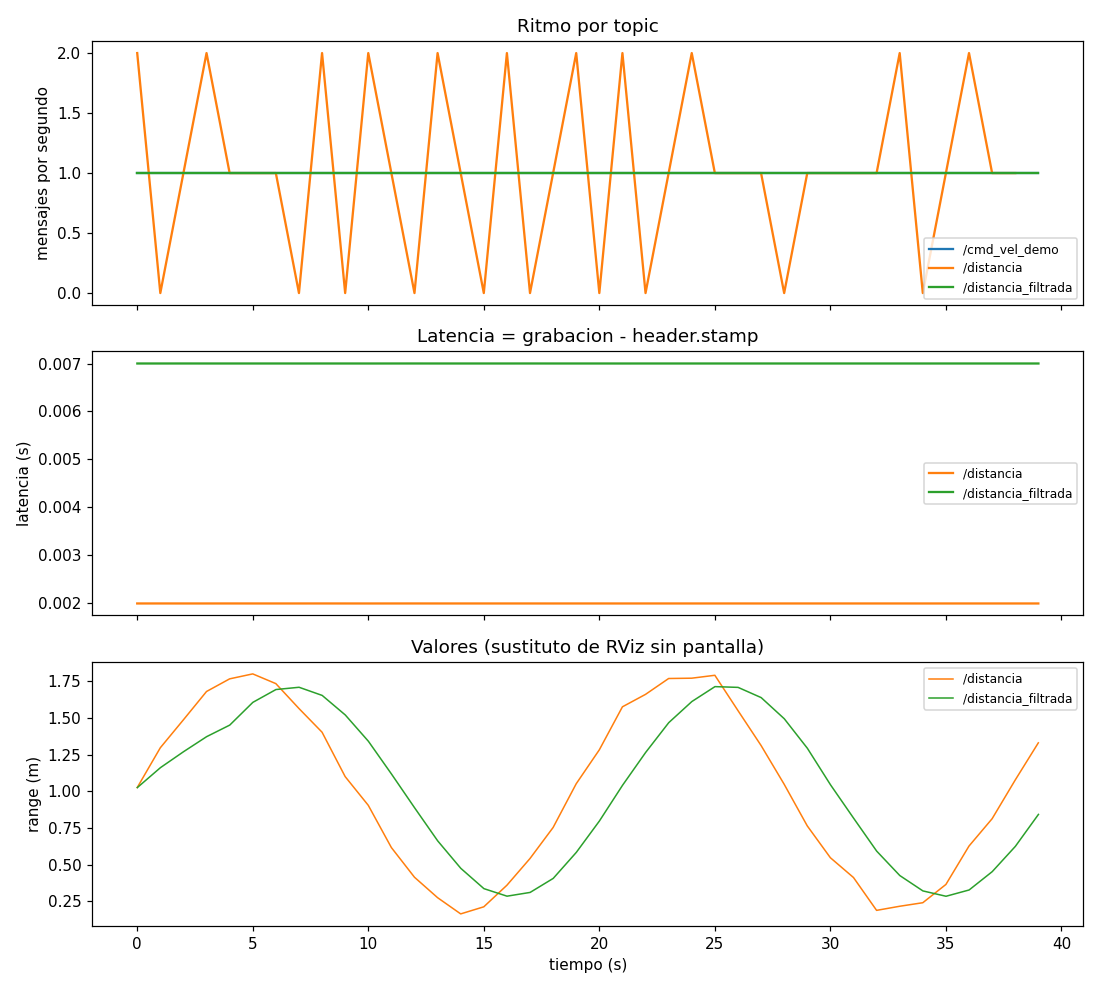

In [ ]:
ab.main(['/content/autonoma/bags/caso_5_casa', '--esperado', '/distancia=10', '--png', '/content/autonoma/informe_caso5.png'])
from IPython.display import Image, display
display(Image('/content/autonoma/informe_caso5.png'))

**Pregunta de control:** sin `--esperado`, la herramienta **supone** 10 Hz para el primer topic de la cadena (mira `main` en `analiza_bag.py`). ¿Qué ocurriría con un sensor diseñado a 1 Hz? ¿Dónde debería vivir realmente el requisito «este sensor publica a N Hz»?

## Ejercicio 2 — Tus propios bags
En la práctica guiada analizaste bags ya hechos. Ahora genera **los tuyos**. Hay dos vías:

- **Con ROS2 (local, opcional, la del enunciado original):** graba el sistema de la S7 sano y con un fallo inyectado (`fallo:=E`) con `ros2 bag record` y analízalos. Esa vía **no se ha probado en este cuaderno**; sigue la guía de la práctica S8 (Parte A2) en tu ordenador.
- **Sin ROS2 (aquí):** usa `simulador_bags.py` (lee su cabecera con `help(sim)`). Genera como mínimo **dos bags con nombre `mi_...`**: uno **sano** y otro **con un fallo que tú elijas** (por ejemplo, un callback lento o un hueco), y un tercero con mensajes **sin cabecera** (`tipo_mensaje='Float32'`).

In [ ]:
help(sim)

Help on module simulador_bags:

NAME
    simulador_bags - simulador_bags.py - fabrica rosbag2 sinteticos del sistema de la S7 (sensor -> filtro -> controlador).

DESCRIPTION
    Sirve para los ejercicios 2 y 4 de la practica autonoma: generar tus PROPIOS bags, sanos o con un fallo
    que tu decidas, y analizarlos con analiza_bag.py (no necesita ROS2; escribe MCAP, el formato por defecto
    de ROS2 Jazzy).

    Uso rapido:
        import simulador_bags as sim
        sim.generar('mi_sano', 'bags')                                   # sistema sano (10 Hz, 40 s)
        sim.generar('mi_hueco', 'bags', hueco=(10, 14))                  # el sensor calla entre 10 s y 14 s
        sim.generar('mi_float', 'bags', tipo_mensaje='Float32')          # mensajes SIN cabecera
        sim.generar('mi_fallo', 'bags', post=mi_funcion)                 # tu propio fallo (ver abajo)

    Parametros de generar():
        frecuencia        Hz del sensor (10 por defecto)
        duracion          segundos de

In [ ]:
# ✏️ Edita los parámetros y ejecuta: sano, con fallo y sin cabecera
sim.generar('mi_sano',  '/content/autonoma/bags')
sim.generar('mi_fallo_a', '/content/autonoma/bags', retardo_filtro=0.4)                        # cambia el fallo
sim.generar('mi_float',  '/content/autonoma/bags', tipo_mensaje='Float32')                      # sano, SIN cabecera
sim.generar('mi_float_lento', '/content/autonoma/bags', tipo_mensaje='Float32', retardo_filtro=0.4)

mi_sano: 1200 mensajes -> /content/autonoma/bags/mi_sano
mi_fallo_a: 598 mensajes -> /content/autonoma/bags/mi_fallo_a
mi_float: 1200 mensajes -> /content/autonoma/bags/mi_float
mi_float_lento: 598 mensajes -> /content/autonoma/bags/mi_float_lento


PosixPath('/content/autonoma/bags/mi_float_lento')

In [ ]:
# Analiza y compara (ritmos, latencia, hallazgos)
for n in ['mi_sano', 'mi_fallo_a', 'mi_float', 'mi_float_lento']:
    print('=' * 70); ab.main([f'/content/autonoma/bags/{n}', '--esperado', '/distancia=10'])

== Informe de mi_sano ==

topic                    tipo                           n      Hz  max dt  lat med
/cmd_vel_demo            Twist                        400   10.00    0.10        -
/distancia               Range                        400   10.00    0.10    0.002
/distancia_filtrada      Range                        400   10.00    0.10    0.007

Hallazgos:
  [INFO ] TODO_OK           -                      ritmos, huecos, latencias y reloj dentro de lo esperado
== Informe de mi_fallo_a ==

topic                    tipo                           n      Hz  max dt  lat med
/cmd_vel_demo            Twist                         99    2.50    0.40        -
/distancia               Range                        400   10.00    0.10    0.002
/distancia_filtrada      Range                         99    2.50    0.40    1.305

Hallazgos:
  [ERROR] CAIDA_EN_CADENA   /distancia_filtrada    /distancia 10.0 Hz -> /distancia_filtrada 2.5 Hz: el ritmo cae en el nodo que une ambos topics
  [E

**Preguntas (respóndelas en tu informe):**
1. Compara `mi_fallo_a` con `mi_float_lento`: **mismo fallo**, distinto tipo de mensaje. ¿Qué hallazgo se pierde en el segundo? ¿Por qué?
2. ¿Qué **no puede medir** la herramienta con mensajes `Float32`? (piensa en latencia y en reloj)
3. ¿Qué harías en el **sistema real** para poder medir latencia aunque el mensaje no tenga cabecera?

## Ejercicio 3 — Extender la herramienta con tu comprobación
La herramienta es **ciega** a algunos fallos. Compruébalo:

In [ ]:
sim.generar('mi_rango', '/content/autonoma/bags', fuera_de_rango=(10, 12, 9.9))   # el sensor publica 9.9 m con max_range = 4 m
ab.main(['/content/autonoma/bags/mi_rango', '--esperado', '/distancia=10'])

mi_rango: 1200 mensajes -> /content/autonoma/bags/mi_rango
== Informe de mi_rango ==

topic                    tipo                           n      Hz  max dt  lat med
/cmd_vel_demo            Twist                        400   10.00    0.10        -
/distancia               Range                        400   10.00    0.10    0.002
/distancia_filtrada      Range                        400   10.00    0.10    0.007

Hallazgos:
  [INFO ] TODO_OK           -                      ritmos, huecos, latencias y reloj dentro de lo esperado


0

`TODO_OK`, pero entre 10 s y 12 s el sensor publicó valores imposibles. Tu tarea: implementar **al menos una** comprobación nueva en `mis_comprobaciones.py` (rangos; la de `frame_id` es ampliación) y **dos pruebas propias** en `PruebasPropias`. Lee las reglas en la cabecera del fichero. ✏️ Edita la celda siguiente y ejecútala para guardar:

In [ ]:
%%writefile /content/autonoma/mis_comprobaciones.py
#!/usr/bin/env python3
"""mis_comprobaciones.py - EJERCICIO 3 de la practica autonoma: extiende la herramienta con TU comprobacion.

analiza_bag.py comprueba ritmos, huecos, latencia y reloj... pero es ciega a otros fallos. Prueba:
    python3 -c "import simulador_bags as s; s.generar('mi_rango', 'bags', fuera_de_rango=(10, 12, 9.9))"
    python3 analiza_bag.py bags/mi_rango --esperado /distancia=10        # dice TODO_OK ... pero el sensor
                                                                         # publico 9.9 m con max_range = 4 m
Tu tarea (elige al menos UNA; la segunda es ampliacion):
    1. comprobar_rangos : valores de `range` fuera de [min_range, max_range]            -> ERROR  RANGO_FUERA
    2. comprobar_frames : mas de un frame_id distinto en un topic                        -> WARN   FRAME_MIXTO
Reglas de la practica:
    - NO cambies los nombres ni las firmas de las funciones (las pruebas de test_mis_comprobaciones.py las usan).
    - Cada comprobacion devuelve una LISTA de Hallazgo (la clase de analiza_bag.py); lista vacia = sin problemas.
    - Escribe, ademas, al menos DOS pruebas propias nuevas en test_mis_comprobaciones.py (clase PruebasPropias).
    - Cuando funcione, integrala (opcional): anade la llamada en analiza_bag.analizar_ruta o usa `main` de este fichero.

Uso:  python3 mis_comprobaciones.py bags/mi_rango /distancia        # codigo de salida 1 si hay ERROR
"""
import sys
from pathlib import Path

from analiza_bag import Hallazgo


def leer_muestras_range(ruta_bag, topic):
    """(YA HECHA) Lee un topic sensor_msgs/Range del bag.

    Devuelve una lista de dicts: {'t': segundos desde el inicio del bag, 'range': float, 'min_range': float,
    'max_range': float, 'frame_id': str}, en orden de grabacion.
    """
    from rosbags.highlevel import AnyReader
    from rosbags.typesys import Stores, get_typestore
    ts = get_typestore(Stores.ROS2_JAZZY)
    out = []
    with AnyReader([Path(ruta_bag)], default_typestore=ts) as r:
        t0 = r.start_time / 1e9
        for conn, t_ns, raw in r.messages():
            if conn.topic != topic:
                continue
            m = r.deserialize(raw, conn.msgtype)
            out.append({'t': t_ns / 1e9 - t0, 'range': float(m.range), 'min_range': float(m.min_range),
                        'max_range': float(m.max_range), 'frame_id': m.header.frame_id})
    return out


def comprobar_rangos(muestras, topic='', margen=0.0):
    """TODO (obligatoria o la otra). Devuelve [] si todas las muestras cumplen
    min_range - margen <= range <= max_range + margen.

    Si alguna no cumple, devuelve UN solo Hallazgo('ERROR', 'RANGO_FUERA', topic, detalle) cuyo detalle diga
    cuantas muestras fallan (de cuantas) y en que intervalo de tiempo ocurren (t de la primera y de la ultima).
    """
    raise NotImplementedError('Ejercicio 3: implementa comprobar_rangos')


def comprobar_frames(muestras, topic=''):
    """TODO (ampliacion). Devuelve [] si todas las muestras tienen el mismo frame_id.

    Si hay mas de uno, devuelve UN Hallazgo('WARN', 'FRAME_MIXTO', topic, detalle) cuyo detalle liste los
    frame_id distintos encontrados.
    """
    raise NotImplementedError('Ejercicio 3 (ampliacion): implementa comprobar_frames')


def main(argv=None):
    argv = sys.argv[1:] if argv is None else argv
    if len(argv) != 2:
        print('uso: mis_comprobaciones.py <carpeta_bag> <topic_range>')
        return 2
    muestras = leer_muestras_range(argv[0], argv[1])
    hallazgos = list(comprobar_rangos(muestras, argv[1]))
    try:
        hallazgos += comprobar_frames(muestras, argv[1])
    except NotImplementedError:
        pass
    if not hallazgos:
        print(f'[INFO ] {argv[1]}: sin problemas de rango ni de frame ({len(muestras)} muestras)')
    for h in hallazgos:
        print(f'[{h.severidad:5s}] {h.codigo:14s} {h.topic}  {h.detalle}')
    return 1 if any(h.severidad == 'ERROR' for h in hallazgos) else 0


if __name__ == '__main__':
    sys.exit(main())


Writing /content/autonoma/mis_comprobaciones.py


✏️ Pruebas (al principio **fallan**: tu trabajo es hacer que pasen). Añade tus dos pruebas en `PruebasPropias`:

In [ ]:
%%writefile /content/autonoma/test_mis_comprobaciones.py
"""Pruebas del ejercicio 3. Al principio FALLAN (NotImplementedError): tu trabajo es hacer que pasen.
Despues, anade tus propias pruebas en la clase PruebasPropias (minimo dos)."""
import tempfile
import unittest

import mis_comprobaciones as mc
import simulador_bags as sim


def m(t, rango, mn=0.02, mx=4.0, frame='sensor_link'):
    return {'t': t, 'range': rango, 'min_range': mn, 'max_range': mx, 'frame_id': frame}


class PruebasRangos(unittest.TestCase):
    def test_todo_en_rango(self):
        self.assertEqual(mc.comprobar_rangos([m(0, 1.0), m(0.1, 3.9), m(0.2, 0.02)], '/d'), [])

    def test_sin_muestras(self):
        self.assertEqual(mc.comprobar_rangos([], '/d'), [])

    def test_por_encima_del_maximo(self):
        h = mc.comprobar_rangos([m(0, 1.0), m(1, 9.9), m(2, 9.9), m(3, 1.0)], '/d')
        self.assertEqual(len(h), 1)
        self.assertEqual((h[0].severidad, h[0].codigo, h[0].topic), ('ERROR', 'RANGO_FUERA', '/d'))
        self.assertIn('2', h[0].detalle)          # 2 muestras fallan

    def test_por_debajo_del_minimo(self):
        h = mc.comprobar_rangos([m(0, 0.001), m(1, 1.0)], '/d')
        self.assertEqual([x.codigo for x in h], ['RANGO_FUERA'])

    def test_margen_de_tolerancia(self):
        muestras = [m(0, 4.05)]
        self.assertEqual(len(mc.comprobar_rangos(muestras, '/d')), 1)
        self.assertEqual(mc.comprobar_rangos(muestras, '/d', margen=0.1), [])

    def test_con_bag_real_sano(self):
        with tempfile.TemporaryDirectory() as d:
            sim.generar('sano', d, duracion=5)
            self.assertEqual(mc.main([f'{d}/sano', '/distancia']), 0)

    def test_con_bag_real_fuera_de_rango(self):
        with tempfile.TemporaryDirectory() as d:
            sim.generar('malo', d, duracion=5, fuera_de_rango=(1, 2, 9.9))
            self.assertEqual(mc.main([f'{d}/malo', '/distancia']), 1)


class PruebasFrames(unittest.TestCase):
    """Ampliacion: se omiten mientras comprobar_frames no este implementada."""
    def setUp(self):
        try:
            mc.comprobar_frames([], '/d')
        except NotImplementedError:
            self.skipTest('comprobar_frames sin implementar (ampliacion)')

    def test_un_solo_frame(self):
        self.assertEqual(mc.comprobar_frames([m(0, 1, frame='a'), m(1, 1, frame='a')], '/d'), [])

    def test_dos_frames(self):
        h = mc.comprobar_frames([m(0, 1, frame='a'), m(1, 1, frame='b')], '/d')
        self.assertEqual(len(h), 1)
        self.assertEqual((h[0].severidad, h[0].codigo), ('WARN', 'FRAME_MIXTO'))
        self.assertIn('a', h[0].detalle)
        self.assertIn('b', h[0].detalle)


class PruebasPropias(unittest.TestCase):
    """TU TRABAJO: anade aqui al menos dos pruebas nuevas (casos limite, otro topic, tu propio fallo...)."""
    pass


if __name__ == '__main__':
    unittest.main()


Writing /content/autonoma/test_mis_comprobaciones.py


In [ ]:
!python -m unittest -v test_mis_comprobaciones 2>&1 | tail -30

NotImplementedError: Ejercicio 3: implementa comprobar_rangos

ERROR: test_sin_muestras (test_mis_comprobaciones.PruebasRangos.test_sin_muestras)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/content/autonoma/test_mis_comprobaciones.py", line 19, in test_sin_muestras
    self.assertEqual(mc.comprobar_rangos([], '/d'), [])
                     ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/content/autonoma/mis_comprobaciones.py", line 53, in comprobar_rangos
    raise NotImplementedError('Ejercicio 3: implementa comprobar_rangos')
NotImplementedError: Ejercicio 3: implementa comprobar_rangos

ERROR: test_todo_en_rango (test_mis_comprobaciones.PruebasRangos.test_todo_en_rango)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/content/autonoma/test_mis_comprobaciones.py", line 16, in test_todo_en_rango
    self.assertEqual(mc.comprobar_rangos([m(0, 1.0), m(0.1, 3.9

In [ ]:
# Resultado sobre el bag con valores imposibles (salida 1 si hay ERROR) y sobre uno sano
!python mis_comprobaciones.py bags/mi_rango /distancia ; echo "salida: $?"
!python mis_comprobaciones.py bags/caso_0_linea_base /distancia ; echo "salida: $?"

Traceback (most recent call last):
  File "/content/autonoma/mis_comprobaciones.py", line 84, in <module>
    sys.exit(main())
             ~~~~^^
  File "/content/autonoma/mis_comprobaciones.py", line 71, in main
    hallazgos = list(comprobar_rangos(muestras, argv[1]))
                     ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/content/autonoma/mis_comprobaciones.py", line 53, in comprobar_rangos
    raise NotImplementedError('Ejercicio 3: implementa comprobar_rangos')
NotImplementedError: Ejercicio 3: implementa comprobar_rangos
salida: 1
Traceback (most recent call last):
  File "/content/autonoma/mis_comprobaciones.py", line 84, in <module>
    sys.exit(main())
             ~~~~^^
  File "/content/autonoma/mis_comprobaciones.py", line 71, in main
    hallazgos = list(comprobar_rangos(muestras, argv[1]))
                     ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/content/autonoma/mis_comprobaciones.py", line 53, in comprobar_rangos
    raise NotImplementedError('Ejercic

**Pregunta:** ¿por qué `RANGO_FUERA` es `ERROR` y `FRAME_MIXTO` `WARN`? ¿Qué falsos positivos podría dar tu comprobación (p. ej., sensores que publican `inf` fuera de alcance)? Respóndelo en tu informe.

## Ejercicio 4 — Un quinto fallo
Diseña un fallo de arquitectura **nuevo** (distinto de los casos 1-5) y genéralo con el parámetro `post` del simulador: una función que recibe la lista de mensajes `(topic, tipo, instante_absoluto, mensaje)` y devuelve la lista modificada (duplicar, retrasar, borrar, reordenar, ráfagas...). Ideas: mensajes duplicados en `/distancia_filtrada`; ráfagas de pérdida; un nodo que se cae y vuelve; un retraso que crece con el tiempo.

Después: analiza tu bag, escribe (a) la **ficha** del fallo sin solución (síntoma observable y qué debe averiguar quien lo resuelva) y (b) la **solución**: cómo se genera, qué hallazgo lo detecta **o por qué la herramienta no lo detecta**, eslabón, familia, causa y arreglo. ¿Tu fallo exige una comprobación nueva en la herramienta (ejercicio 3)? Entonces, ¡bien!

In [ ]:
# ✏️ Tu fallo
def mi_fallo(msgs):
    salida = []
    for topic, tipo, t, msg in msgs:
        salida.append((topic, tipo, t, msg))
        # EJEMPLO (cámbialo por el tuyo): el filtro publica cada mensaje dos veces
        if topic == '/distancia_filtrada':
            salida.append((topic, tipo, t + 0.01, msg))
    return salida

sim.generar('mi_fallo_b', '/content/autonoma/bags', post=mi_fallo)
ab.main(['/content/autonoma/bags/mi_fallo_b', '--esperado', '/distancia=10'])

mi_fallo_b: 1600 mensajes -> /content/autonoma/bags/mi_fallo_b
== Informe de mi_fallo_b ==

topic                    tipo                           n      Hz  max dt  lat med
/cmd_vel_demo            Twist                        400   10.00    0.10        -
/distancia               Range                        400   10.00    0.10    0.002
/distancia_filtrada      Range                        800   20.02    0.09    0.012

Hallazgos:
  [ERROR] CAIDA_EN_CADENA   /cmd_vel_demo          /distancia_filtrada 20.0 Hz -> /cmd_vel_demo 10.0 Hz: el ritmo cae en el nodo que une ambos topics


1

In [ ]:
# Empaqueta el reto SIN pistas en el nombre (carpeta reto/); rellena después su ficha (solo síntoma, sin solución)
!python empaquetar_reto.py bags/mi_fallo_b reto/
!ls reto

Bag copiado en reto/reto_1; rellena reto_1_ficha.md (sin la solucion)
reto_1	reto_1_ficha.md


Intercambia **solo** `reto/reto_N` y su ficha con un compañero (en Colab: Archivos → descargar la carpeta, o comparte tu cuaderno sin las celdas de solución). Cuando te devuelva su resolución, anota en tu informe si acertó y qué le faltó.

## Ejercicio 5 — Lista de comprobación ampliada
En la práctica guiada recorriste **7 preguntas** (de las baratas a las caras). Amplíalas con **3 más** (8-10), cada una con: pregunta, herramienta, qué detecta y **un caso que la justifique** (puede ser real: otra asignatura, prácticas, un TFG). Rellena la tabla en la sección «Ejercicio 5» de tu informe (celda ✏️ del informe).

## Ejercicio 6 — Autoformación guiada
Completa los puntos de control de la *Guía de autoformación de la S8* (rosbag2 avanzado, RViz2/tf2 y depuración de arquitectura) y resume en la sección «Ejercicio 6» lo aprendido y tus dudas.

## Opcional — con ROS2 en tu ordenador
Reproduce cada bag con `ros2 bag play` y observa `/distancia` y `/distancia_filtrada` con `ros2 topic hz` y RViz2 (display *Range*). **No probado** con estos bags sintéticos: anota cualquier diferencia que encuentres.

## Reflexión final
Escribe 5 líneas al final de tu informe: lo más difícil, qué cambiarías en la herramienta y qué le faltó al bag para estar seguro de la causa.

## Ejercicio 7 — Repositorio Git con integración continua (S9)
Convierte tu trabajo en un repositorio **con historia** y con **integración continua**. Requisitos (rúbrica en el enunciado):

1. **Historial:** mínimo 6 commits con mensajes que digan *qué* y *por qué*, hechos a medida que trabajas (no uno solo al final).
2. **Rama + fusión:** una rama de trabajo (p. ej. `ej3-rango`) integrada en `main` con un *Pull Request* (o, como mínimo, un `merge`).
3. **CI en verde:** el workflow `.github/workflows/ci.yml` ejecuta las pruebas de la herramienta, **tus** pruebas y la regresión con bags. Enlaza la ejecución.
4. **Rojo → verde:** rompe la CI **a propósito** (un umbral, un valor esperado), enlaza la ejecución en rojo, diagnostícala en el log y arréglala.
5. **Contrato ampliado:** añade tu `mi_rango` (y tu reto) a `esperado.json`.

Aquí puedes hacer Git en local y comprobar la CI con `simula_ci.py` (no es un runner real). Lo de GitHub se hace fuera del cuaderno.

In [17]:
# Git local dentro de Colab (identidad de ejemplo: ponla tuya, SIN contraseñas ni tokens)
!git config --global user.email "marinajimenezcoronado@gmail.com"
!git config --global user.name "Marina Jiménez"
!git init -b main 2>&1 | tail -1
!git add -A && git commit -qm "Punto de partida de la P2" && git log --oneline

Initialized empty Git repository in /content/autonoma/.git/
0c2df35 (HEAD -> main) Punto de partida de la P2


✏️ Añade tu bag `mi_rango` al contrato (cámbialo si tu herramienta ya detecta el fallo: entonces `salida` es 1 y `errores` es `["RANGO_FUERA"]`) y comprueba la regresión:

In [ ]:
import json
c = json.load(open('esperado.json'))
c['bags']['mi_rango'] = {'salida': 0, 'errores': []}      # ✏️ hoy la herramienta original es CIEGA a este fallo: salida 0
json.dump(c, open('esperado.json', 'w'), indent=2, ensure_ascii=False)
!python regresion_bags.py | tail -3

[OK   ] mi_rango             errores = ninguno

6/6 bags con el diagnostico esperado


In [ ]:
# La CI "de bolsillo": los mismos pasos que ejecutará GitHub Actions (las acciones `uses:` se saltan)
!python simula_ci.py .github/workflows/ci.yml | tail -4

[8] (lo hace GitHub, aqui se salta) uses: actions/upload-artifact@v7  <- Guardar informe como artefacto
=== job pruebas: ROJO ===

RESULTADO: ROJO (la integracion continua fallaria)


In [ ]:
# Trabaja por ramas: crea una rama, haz un commit y fusiónala (ejemplo; adáptalo a tu trabajo real)
!git checkout -q -b ej3-rango
!git add -A && git commit -qm "Ejercicio 3: comprobacion de rangos y sus pruebas" ; true
!git checkout -q main && git merge --no-ff -q ej3-rango -m "Fusiona ej3-rango" ; git log --oneline --graph --all

*   b13e5a7 (HEAD -> main) Fusiona ej3-rango
|\  
| * ca603f3 (ej3-rango) Ejercicio 3: comprobacion de rangos y sus pruebas
|/  
* 6fa88ac Punto de partida de la P2


In [ ]:
# Evidencia del historial para la entrega (repite tras cada commit nuevo)
!git log --oneline --graph --all > evidencias/git_log.txt
!wc -l evidencias/git_log.txt

5 evidencias/git_log.txt


**Subir a GitHub (fuera del cuaderno):** descarga el contenido (`Archivos → descargar`, o el `.zip` de entrega), crea un repositorio en GitHub y súbelo desde tu ordenador con `git push`, o desde la web (*Add file → Upload files*; **ojo:** la web no sube bien carpetas ocultas como `.github`, créalo desde tu ordenador si falla). **No pegues tokens ni contraseñas en este cuaderno ni en capturas.** Después: provoca el rojo, arréglalo, guarda las capturas como `evidencias/ci_rojo.png` y `evidencias/ci_verde.png` y copia las URL en la sección «Ejercicio 7» del informe. Si no puedes usar GitHub, guarda en `ci_rojo.txt` y `ci_verde.txt` la salida de `simula_ci.py` en rojo y en verde y explícalo en el informe (la nota máxima del ejercicio baja: ver enunciado).

## Memoria conceptual (M1-M4)
Responde en la sección «Memoria conceptual» de tu informe, con **tus palabras** (máximo 1 página en total): M1 familias de fallo con un ejemplo y la herramienta más barata para cada una; M2 por qué una herramienta de análisis necesita pruebas y qué significa «un fallo no detectado es una especificación pendiente»; M3 qué es un conflicto de fusión, cómo se ve y cómo se resuelve; M4 qué garantiza y qué no una CI en verde.

## Entrega
1. Ejecuta la autocomprobación (revisa **solo lo formal**: no valora si tu diagnóstico es correcto).
2. Crea el `.zip` y descárgalo. **Hazlo antes de cerrar Colab.**

In [ ]:
!python entrega.py

[FALTA] Informe - Declaración de autoría y uso de IA: 2 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 1 — Caso 5 (`bags/caso_5_casa`): 8 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 2 — Mis propios bags: 4 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 3 — Extensión de la herramienta: 5 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 4 — Un quinto fallo: 7 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 5 — Lista de comprobación ampliada: 3 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 6 — Autoformación guiada: 1 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 7 — Repositorio Git con integración continua: 7 campo(s) sin rellenar
[FALTA] Informe - Memoria conceptual (con tus palabras; máximo 1 página en total): 4 campo(s) sin rellenar
[FALTA] Informe - Reflexión final (5 líneas): 1 campo(s) sin rellenar
[ OK ] Ejercicio 2: bags propios en bags/mi_* (6 encontrados, minimo 2): mi_fallo_a, mi_fallo_b, mi_float, mi_float_lento, mi_rango, mi_sano
[FALTA] Ejercicio 3: pr

In [ ]:
!python entrega.py --zip Apellido_Nombre
try:
    from google.colab import files
    files.download('/content/autonoma/entrega_Apellido_Nombre.zip')
except ImportError:
    print('Fuera de Colab: el .zip esta en /content/autonoma/')

[FALTA] Informe - Declaración de autoría y uso de IA: 2 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 1 — Caso 5 (`bags/caso_5_casa`): 8 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 2 — Mis propios bags: 4 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 3 — Extensión de la herramienta: 5 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 4 — Un quinto fallo: 7 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 5 — Lista de comprobación ampliada: 3 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 6 — Autoformación guiada: 1 campo(s) sin rellenar
[FALTA] Informe - Ejercicio 7 — Repositorio Git con integración continua: 7 campo(s) sin rellenar
[FALTA] Informe - Memoria conceptual (con tus palabras; máximo 1 página en total): 4 campo(s) sin rellenar
[FALTA] Informe - Reflexión final (5 líneas): 1 campo(s) sin rellenar
[ OK ] Ejercicio 2: bags propios en bags/mi_* (6 encontrados, minimo 2): mi_fallo_a, mi_fallo_b, mi_float, mi_float_lento, mi_rango, mi_sano
[FALTA] Ejercicio 3: pr

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cierre
Un bag convierte un fallo que ocurre una vez en un fallo que puedes **estudiar muchas veces**; una comprobación con su prueba convierte lo que has entendido en algo que **vigila por ti**. Con Git y CI (ejercicio 7) esa comprobación se ejecuta sola, en cada cambio: el sistema deja de depender de que *tú te acuerdes* de comprobarlo.